# Predicting GitHub Developer Fields from a Mutual-Follow Network

**Final project — Graph Algorithms**

Noa Yarin Levy · Jimi Halawi · Ofir Atias  
Instructor: Dr. Avner Priel

This project studies an undirected network of 37,700 GitHub developers and 289,003 mutual-follow links. The validated core uses course methods; sparse content features provide a controlled reference point rather than replacing network analysis.

## 1. Motivation and research questions

The project asks whether GitHub mutual-follow structure is associated with developer field. It studies node classification, network versus content features, static edge reconstruction, and null-model comparisons. All claims are descriptive; the analysis does not claim causality.

## 2. Execution environment and reproducibility

All repeated experiments use fixed seeds 42, 7, 21, 84, and 123. Word2Vec uses one worker for deterministic training. For the closest bit-level reproduction, set `PYTHONHASHSEED=0` before starting the kernel. The setup cell locates the project, registers source and output paths, and records the hash-seed state.

In [1]:
from pathlib import Path
import os, random, sys
import numpy as np
import pandas as pd
from IPython.display import Image, display

PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / "src").exists():
    PROJECT_DIR = PROJECT_DIR.parent
SRC_DIR = PROJECT_DIR / "src"
sys.path.insert(0, str(SRC_DIR))
TABLES_DIR = PROJECT_DIR / "outputs" / "tables"
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
SEEDS = (42, 7, 21, 84, 123)
random.seed(42)
np.random.seed(42)
print(f"Project: {PROJECT_DIR}")
print(f"PYTHONHASHSEED={os.environ.get('PYTHONHASHSEED', 'not set (set to 0 before launch)')}")

Project: C:\Users\Jimi\Desktop\github-social-network
PYTHONHASHSEED=0


## 3. Data preparation and quality checks

The input is the June 2019 MUSAE GitHub Social Network: an edge list, one binary target per node, and sparse content features. Before analysis, the pipeline checks duplicate undirected edges, self-loops, missing labels, node-set alignment, and graph connectivity. The following workflow call regenerates the core tables and displays both the validation results and basic network statistics.

Computing centralities ...


Core analysis completed.
 num_nodes  num_edges  density  average_degree  num_connected_components  largest_component_size  largest_component_ratio  labeled_nodes_total  labeled_nodes_in_graph  labeled_node_ratio  homophily_rate  same_label_edges  different_label_edges  labeled_edges
     37700     289003 0.000407       15.331724                         1                   37700                      1.0                37700                   37700                 1.0        0.845344            244307                  44696         289003
 number_of_communities  modularity  largest_community_size  median_community_size  size_weighted_mean_purity
                    31    0.453448                    8732                    9.0                   0.829788


,check,value,passed
0,raw_edge_rows,289003,True
1,graph_nodes,37700,True
2,graph_edges,289003,True
3,self_loops,0,True
4,duplicate_undirected_edges,0,True
5,duplicate_label_ids,0,True
6,missing_labels,0,True
7,all_graph_nodes_labeled,1,True
8,connected_components,1,True


,num_nodes,num_edges,density,average_degree,num_connected_components,largest_component_size,largest_component_ratio,labeled_nodes_total,labeled_nodes_in_graph,labeled_node_ratio,homophily_rate,same_label_edges,different_label_edges,labeled_edges
0,37700,289003,0.00041,15.33172,1,37700,1.0,37700,37700,1.0,0.84534,244307,44696,289003


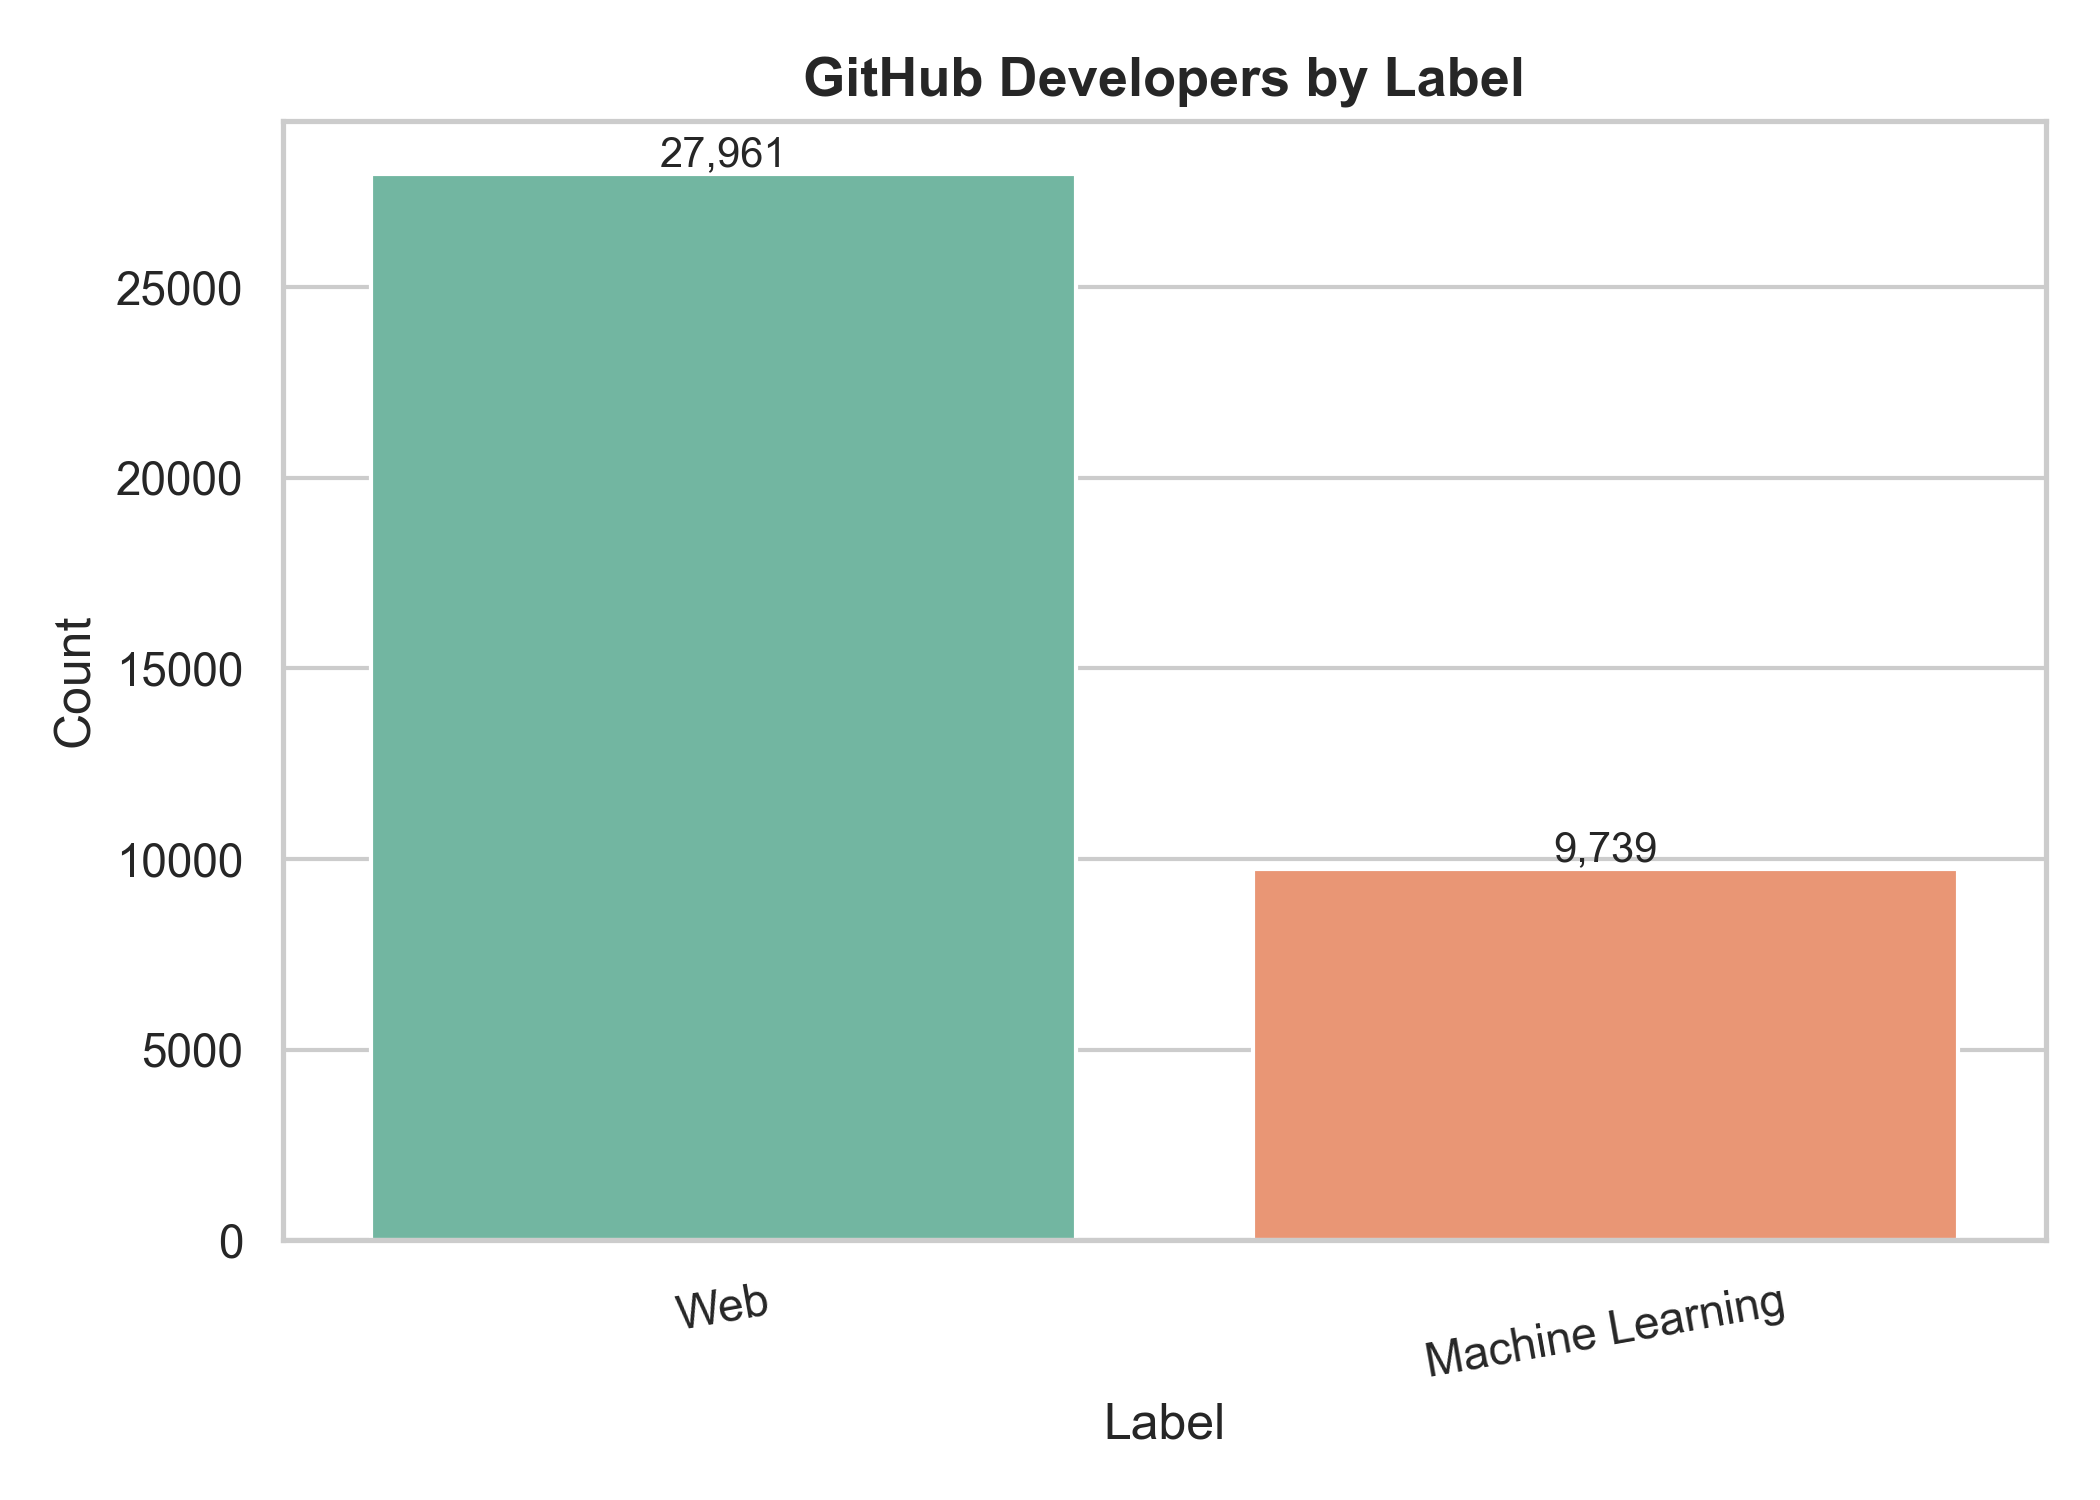

In [2]:
from run_core_analysis import main as run_core_analysis
run_core_analysis()
display(pd.read_csv(TABLES_DIR / "data_quality_checks.csv"))
display(pd.read_csv(TABLES_DIR / "network_basic_stats.csv").round(5))
display(Image(filename=str(FIGURES_DIR / "label_distribution.png")))

### Network description

The network contains 37,700 nodes and 289,003 edges, with no self-loops or duplicate undirected edges, and forms one connected component. Same-field endpoints account for 84.5% of edges. This is a strong descriptive relationship, but by itself it does not separate class imbalance, degree distribution, and community structure.

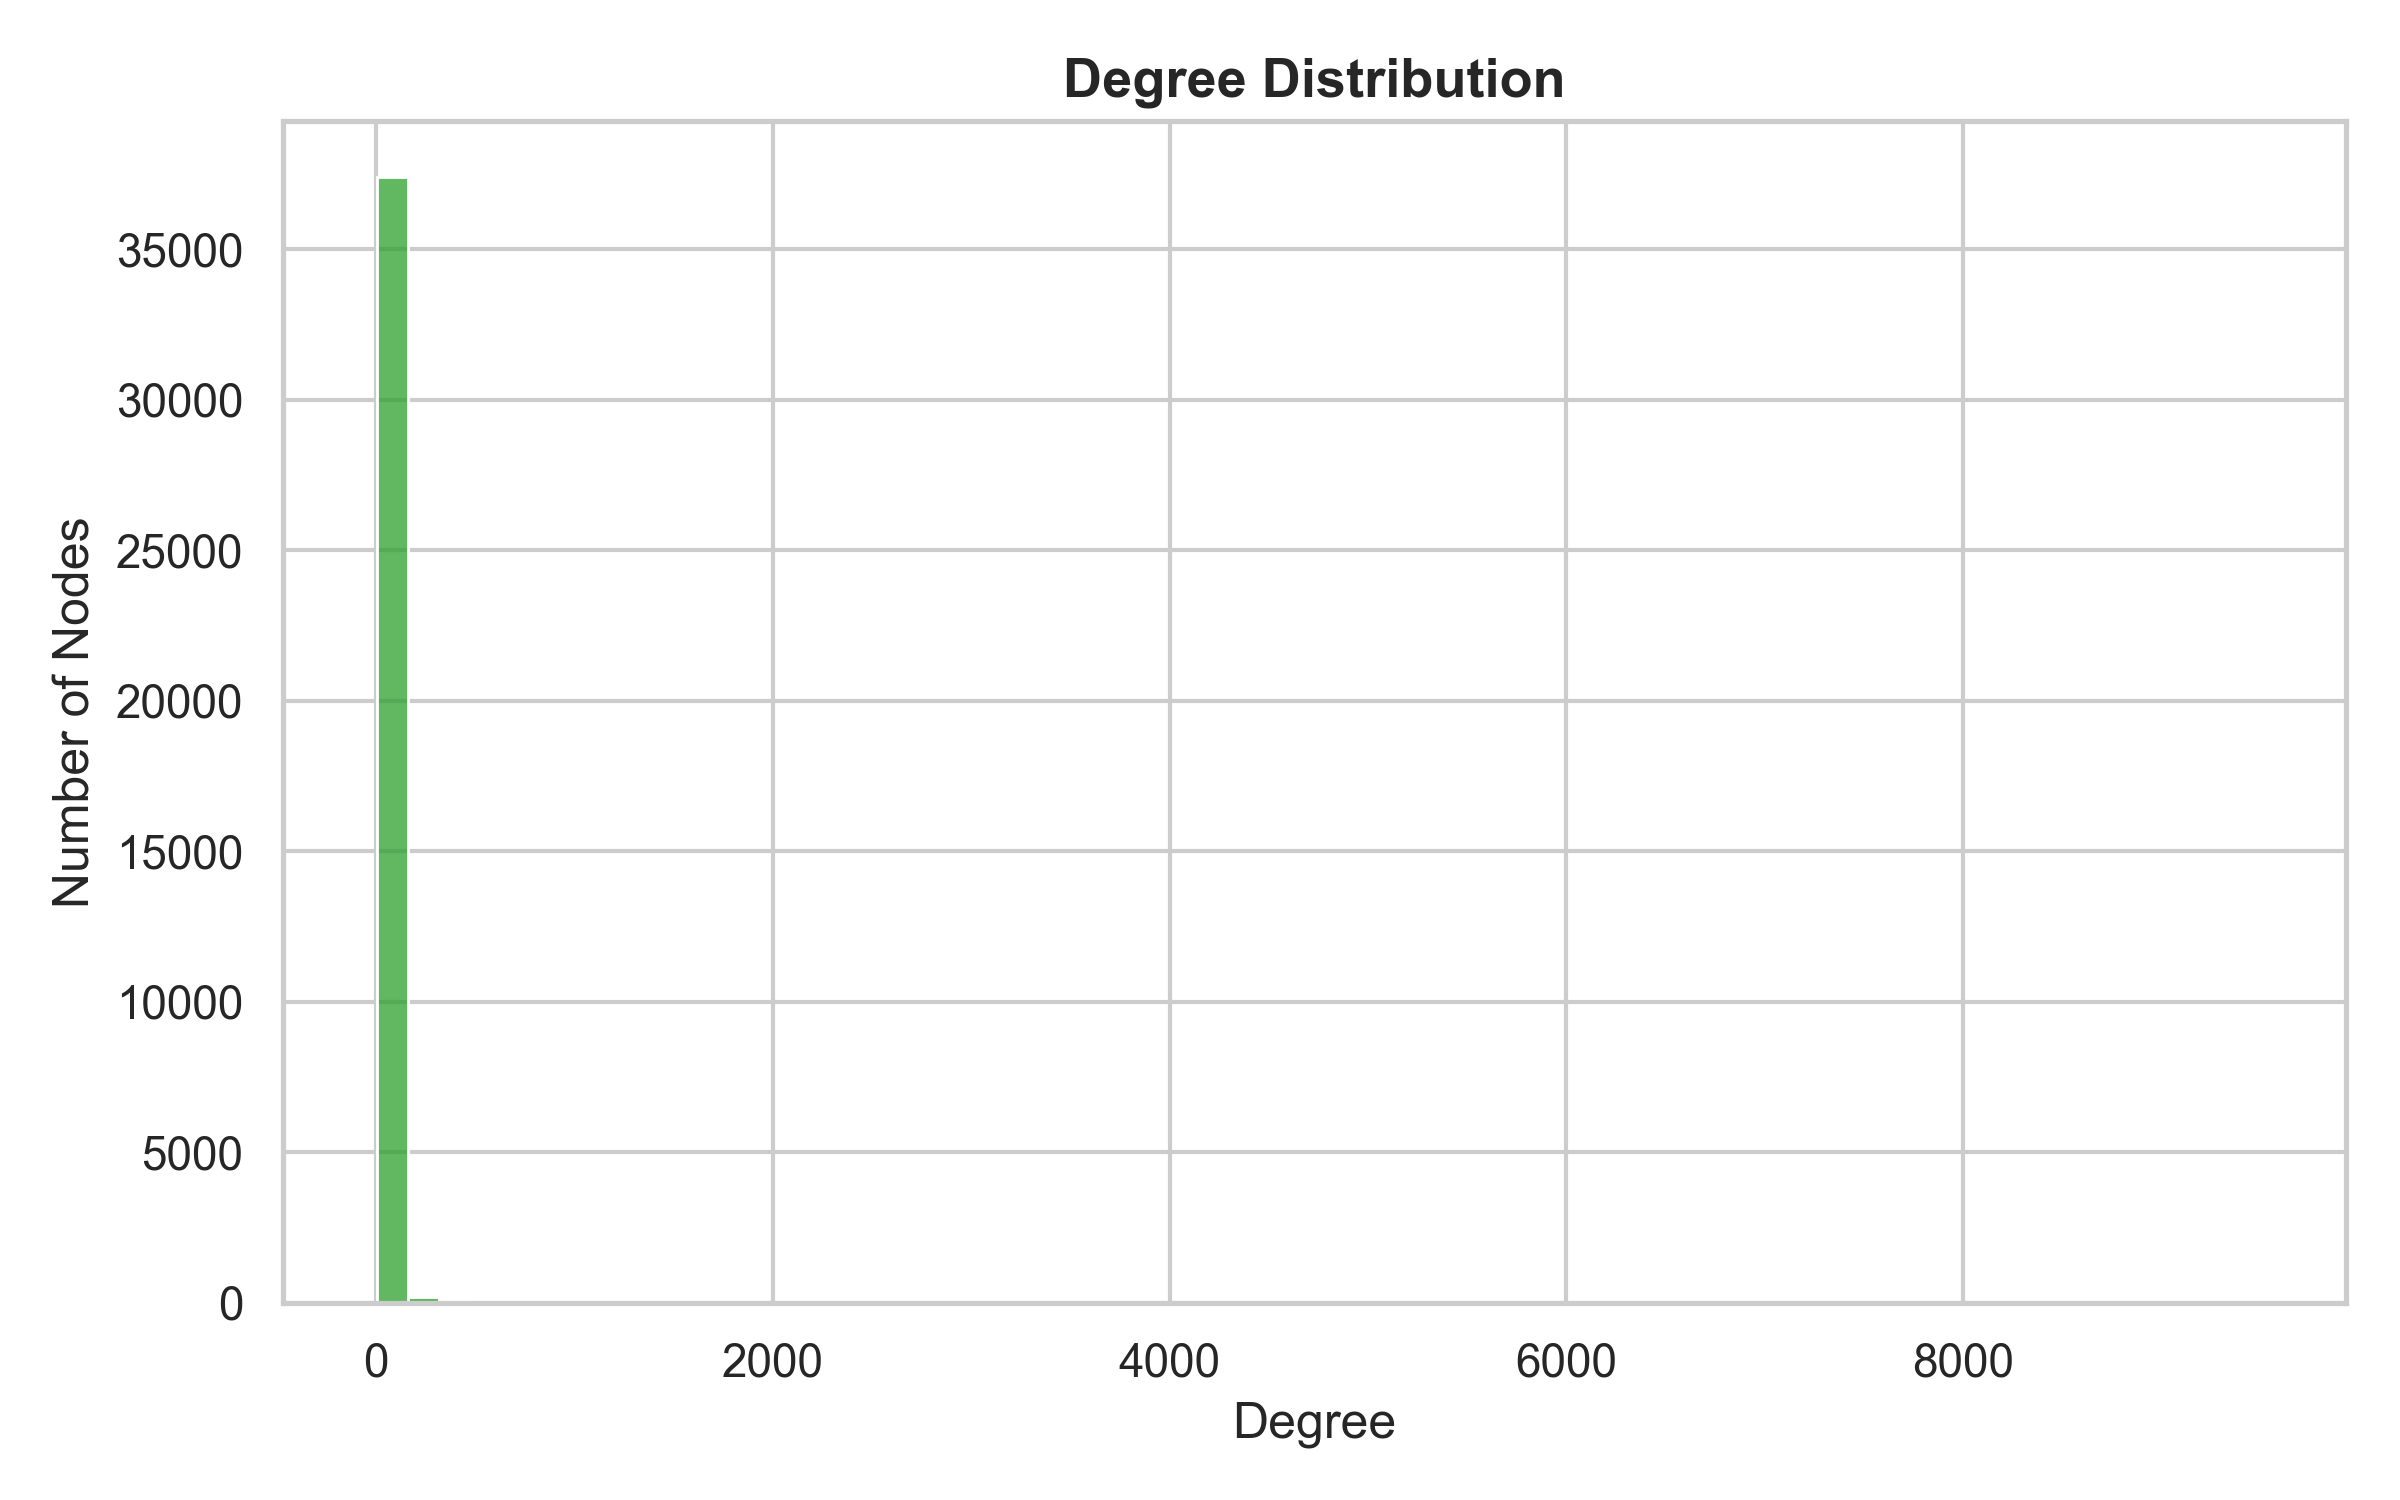

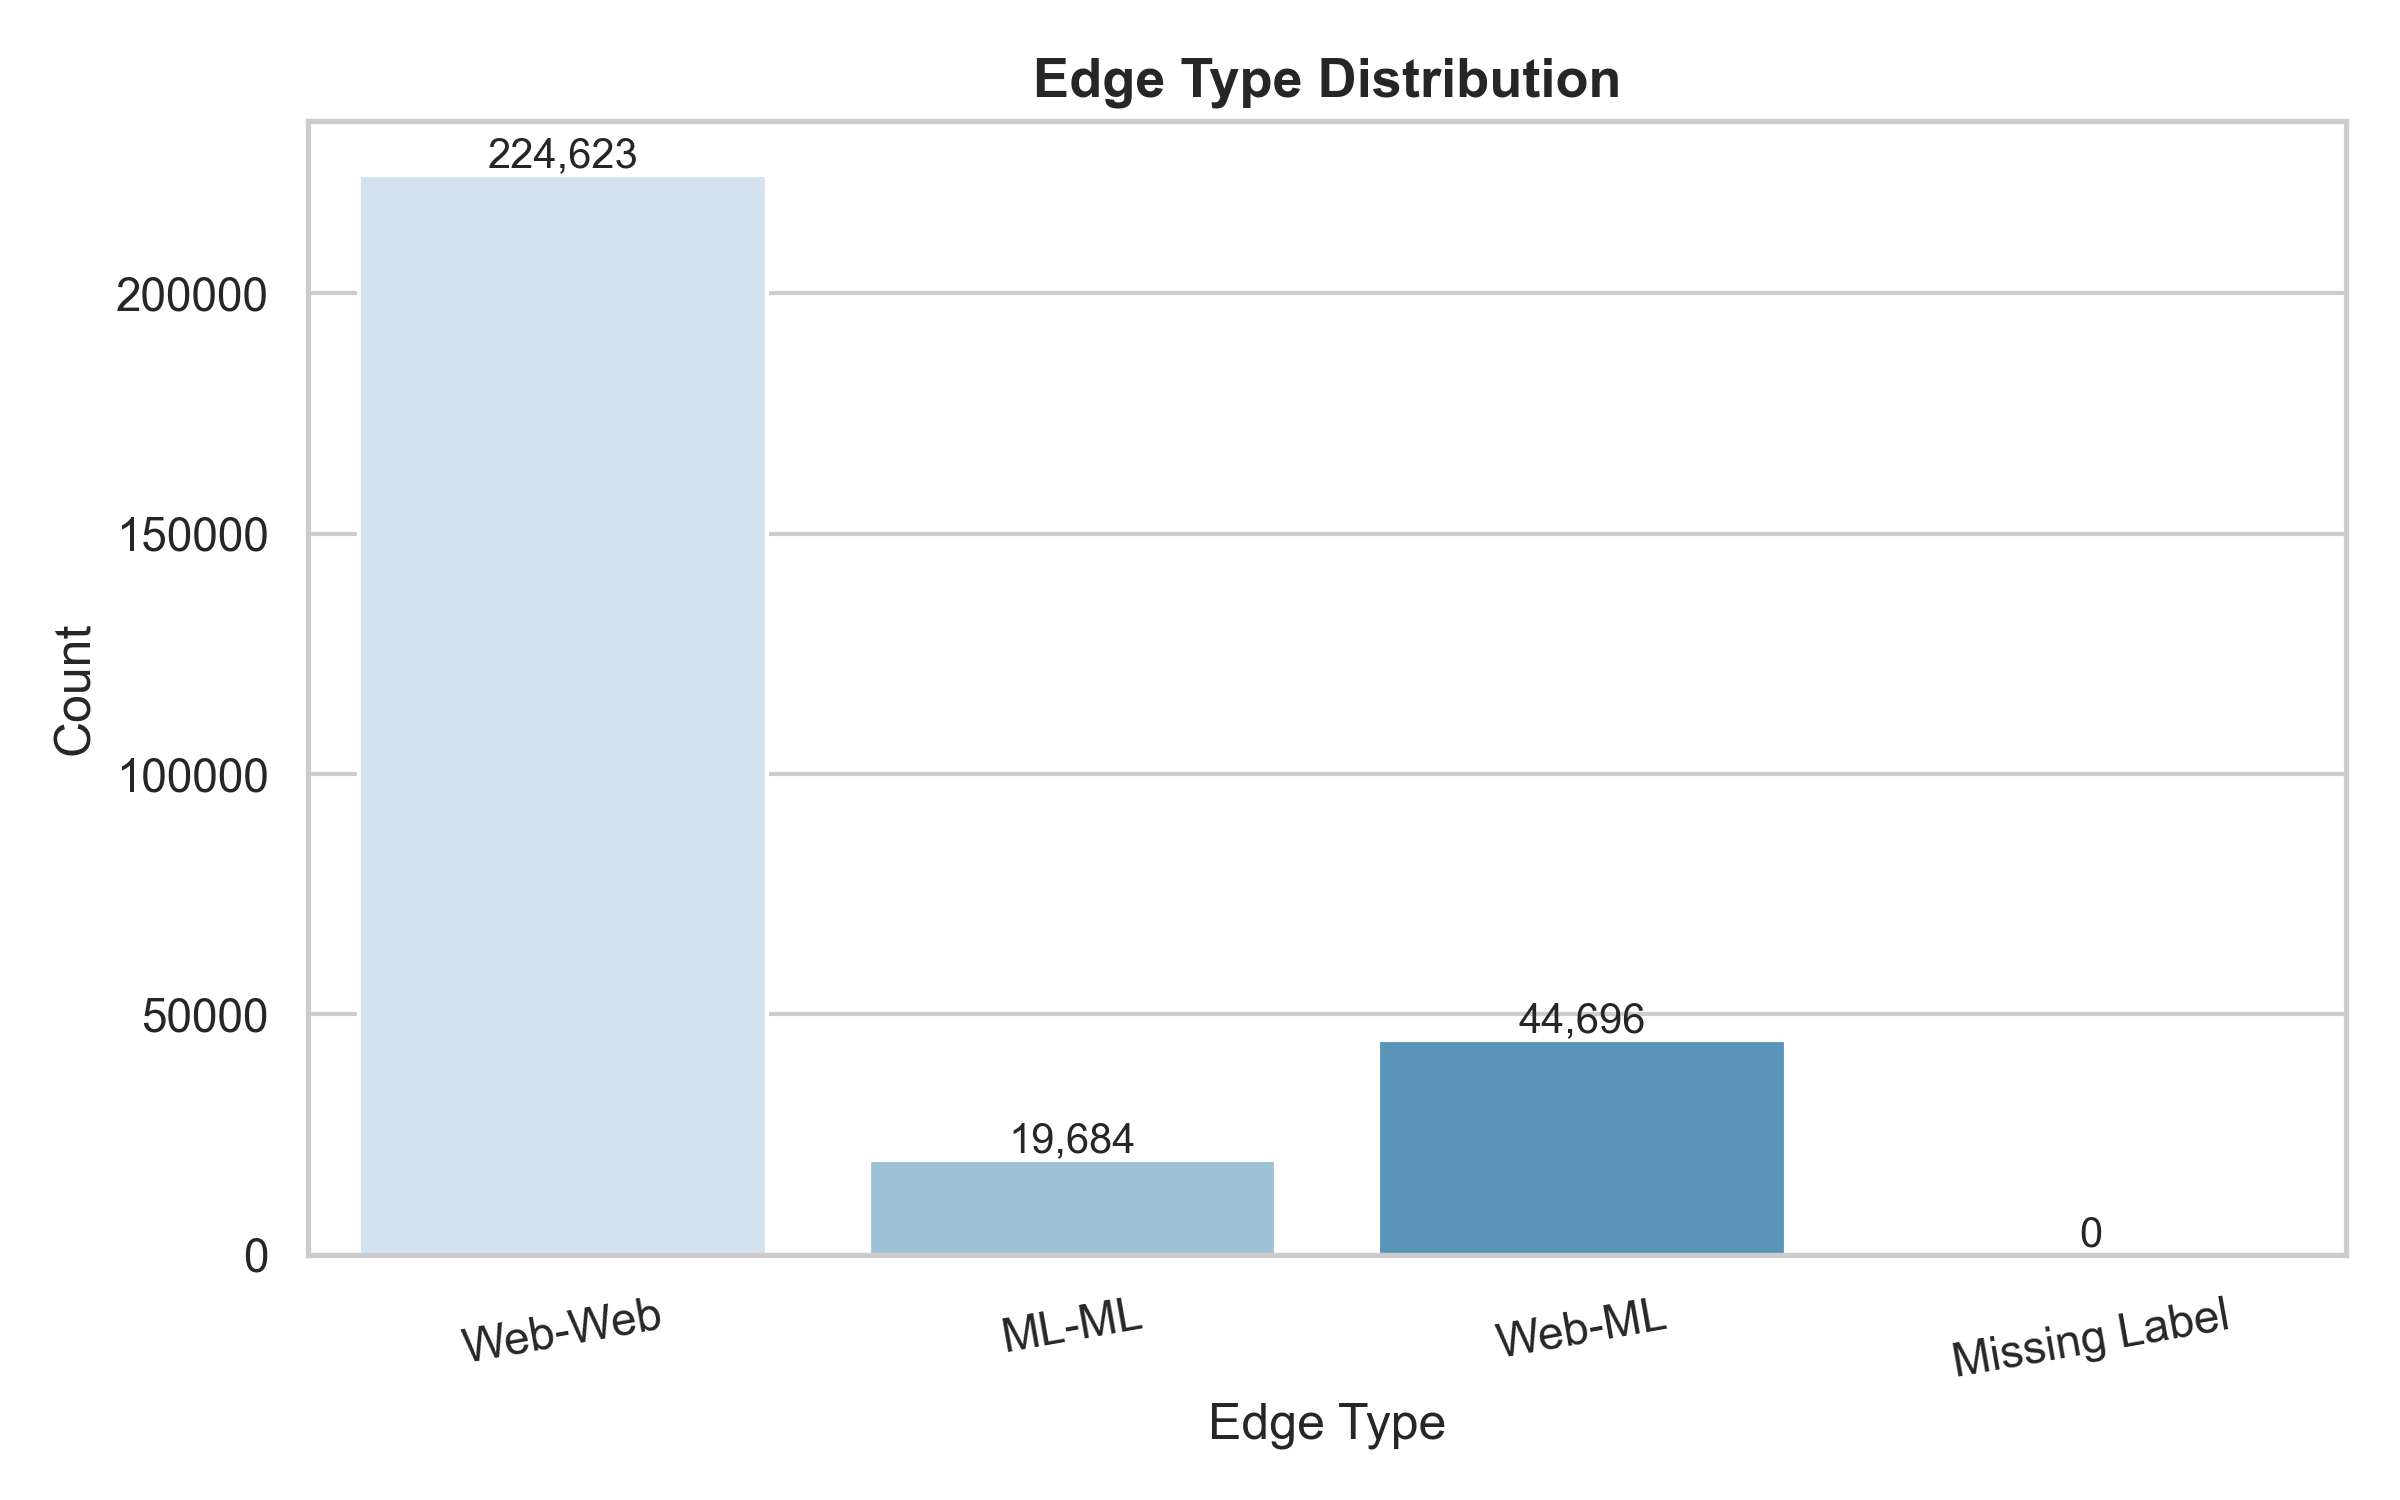

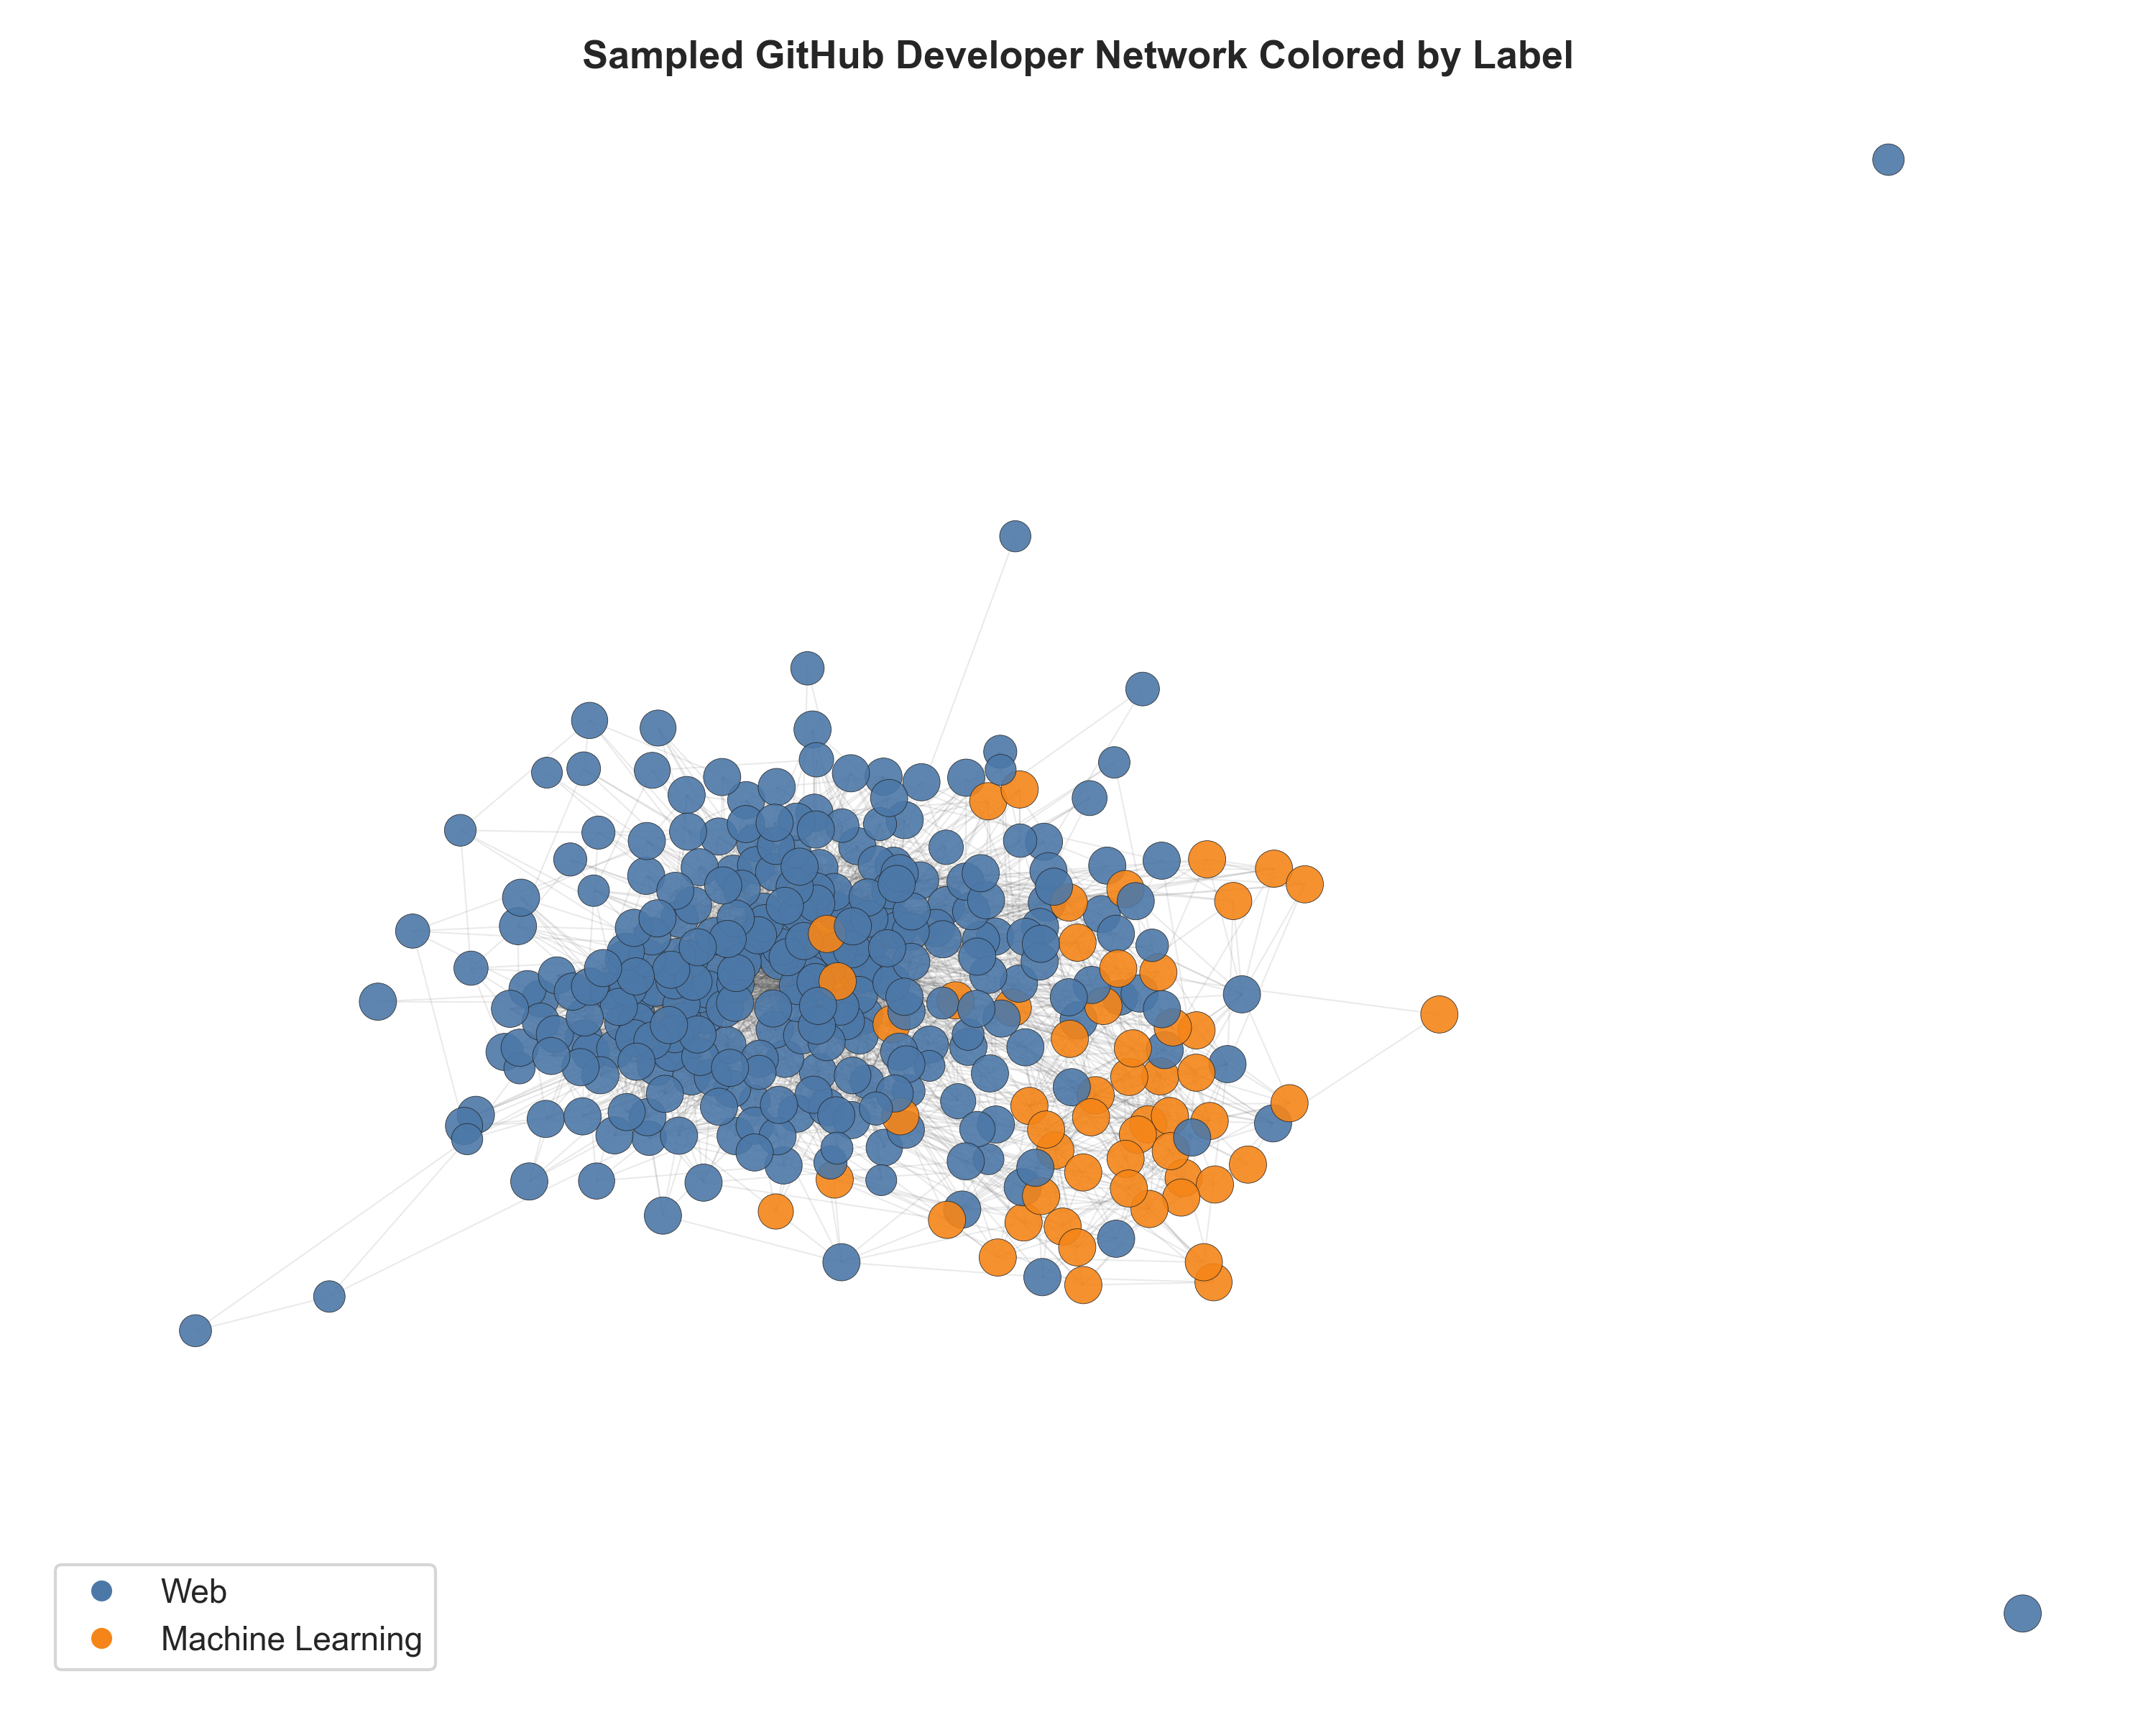

In [3]:
display(Image(filename=str(FIGURES_DIR / "degree_distribution.png")))
display(Image(filename=str(FIGURES_DIR / "edge_type_distribution.png")))
display(Image(filename=str(FIGURES_DIR / "sampled_network_by_label.png")))

## 4. Centrality: popularity, recursive importance, and brokerage

- **Degree Centrality** emphasizes direct connectivity; dalinhuang99 (node 31890, degree 9,458) ranks first.
- **PageRank** also weights neighbor importance; dalinhuang99 remains first.
- **Betweenness Centrality** emphasizes shortest-path brokerage; with 100 sampled sources, nfultz (node 27803, degree 7,085) ranks first.
- Top-20 Jaccard overlap is 1.000 between Degree and PageRank but 0.600 between Degree and sampled Betweenness. The measures are therefore not interchangeable: Degree and PageRank identify hubs, while Betweenness can identify bridges.

Only one HITS hub score is kept because hub and authority scores are redundant in an undirected graph.

In [4]:
centrality_top = pd.read_csv(TABLES_DIR / "centrality_top_developers.csv")
display(centrality_top.groupby("metric", group_keys=False).head(5).round(6))
display(pd.read_csv(TABLES_DIR / "centrality_top_overlap.csv").round(3))

,metric,rank,node_id,developer_name,field,score,degree,pagerank,betweenness_approx,clustering_coefficient
0,Degree Centrality,1,31890,dalinhuang99,Web,0.250882,9458,0.016514,0.238360,0.001413
1,Degree Centrality,2,27803,nfultz,Web,0.187936,7085,0.011451,0.270590,0.003199
2,Degree Centrality,3,35773,addyosmani,Web,0.088172,3324,0.004919,0.052829,0.004121
3,Degree Centrality,4,19222,Bunlong,Web,0.078464,2958,0.004669,0.063271,0.006373
4,Degree Centrality,5,13638,gabrielpconceicao,Web,0.065466,2468,0.003875,0.036141,0.006492
10,PageRank,1,31890,dalinhuang99,Web,0.016514,9458,0.016514,0.238360,0.001413
11,PageRank,2,27803,nfultz,Web,0.011451,7085,0.011451,0.270590,0.003199
12,PageRank,3,35773,addyosmani,Web,0.004919,3324,0.004919,0.052829,0.004121
13,PageRank,4,19222,Bunlong,Web,0.004669,2958,0.004669,0.063271,0.006373
14,PageRank,5,13638,gabrielpconceicao,Web,0.003875,2468,0.003875,0.036141,0.006492


,metric_a,metric_b,top_k,intersection_count,jaccard_overlap
0,Degree Centrality,PageRank,20,20,1.000
1,Degree Centrality,"Betweenness Centrality (approx., k=100)",20,15,0.600
2,Degree Centrality,Clustering Coefficient,20,0,0.000
3,Degree Centrality,HITS Hub,20,17,0.739
4,PageRank,"Betweenness Centrality (approx., k=100)",20,15,0.600
5,PageRank,Clustering Coefficient,20,0,0.000
6,PageRank,HITS Hub,20,17,0.739
7,"Betweenness Centrality (approx., k=100)",Clustering Coefficient,20,0,0.000
8,"Betweenness Centrality (approx., k=100)",HITS Hub,20,14,0.538
9,Clustering Coefficient,HITS Hub,20,0,0.000


## 5. Louvain communities

Louvain finds 31 communities with modularity 0.453. The largest community contains 8,732 developers and size-weighted purity is 0.830.

- Community 7: 8,732 nodes, 6.5% ML
- Community 2: 7,664 nodes, 71.5% ML
- Community 13: 6,454 nodes, 19.4% ML

The composition differences show that community structure is associated with field, but mixed communities prevent perfect identification and should not be interpreted as rigid professional identities.

,number_of_communities,modularity,largest_community_size,median_community_size,size_weighted_mean_purity
0,31,0.4534,8732,9.0,0.8298


,community_id,size,web_count,ml_count,web_ratio,ml_ratio,dominant_label,purity
0,7,8732,8165,567,0.935,0.065,Web,0.935
1,2,7664,2181,5483,0.285,0.715,ML,0.715
2,13,6454,5205,1249,0.806,0.194,Web,0.806
3,0,3047,2587,460,0.849,0.151,Web,0.849
4,5,2702,2534,168,0.938,0.062,Web,0.938
5,11,2396,1750,646,0.730,0.270,Web,0.730
6,8,2087,1902,185,0.911,0.089,Web,0.911
7,3,2000,1563,437,0.782,0.218,Web,0.782
8,4,904,649,255,0.718,0.282,Web,0.718
9,10,566,472,94,0.834,0.166,Web,0.834


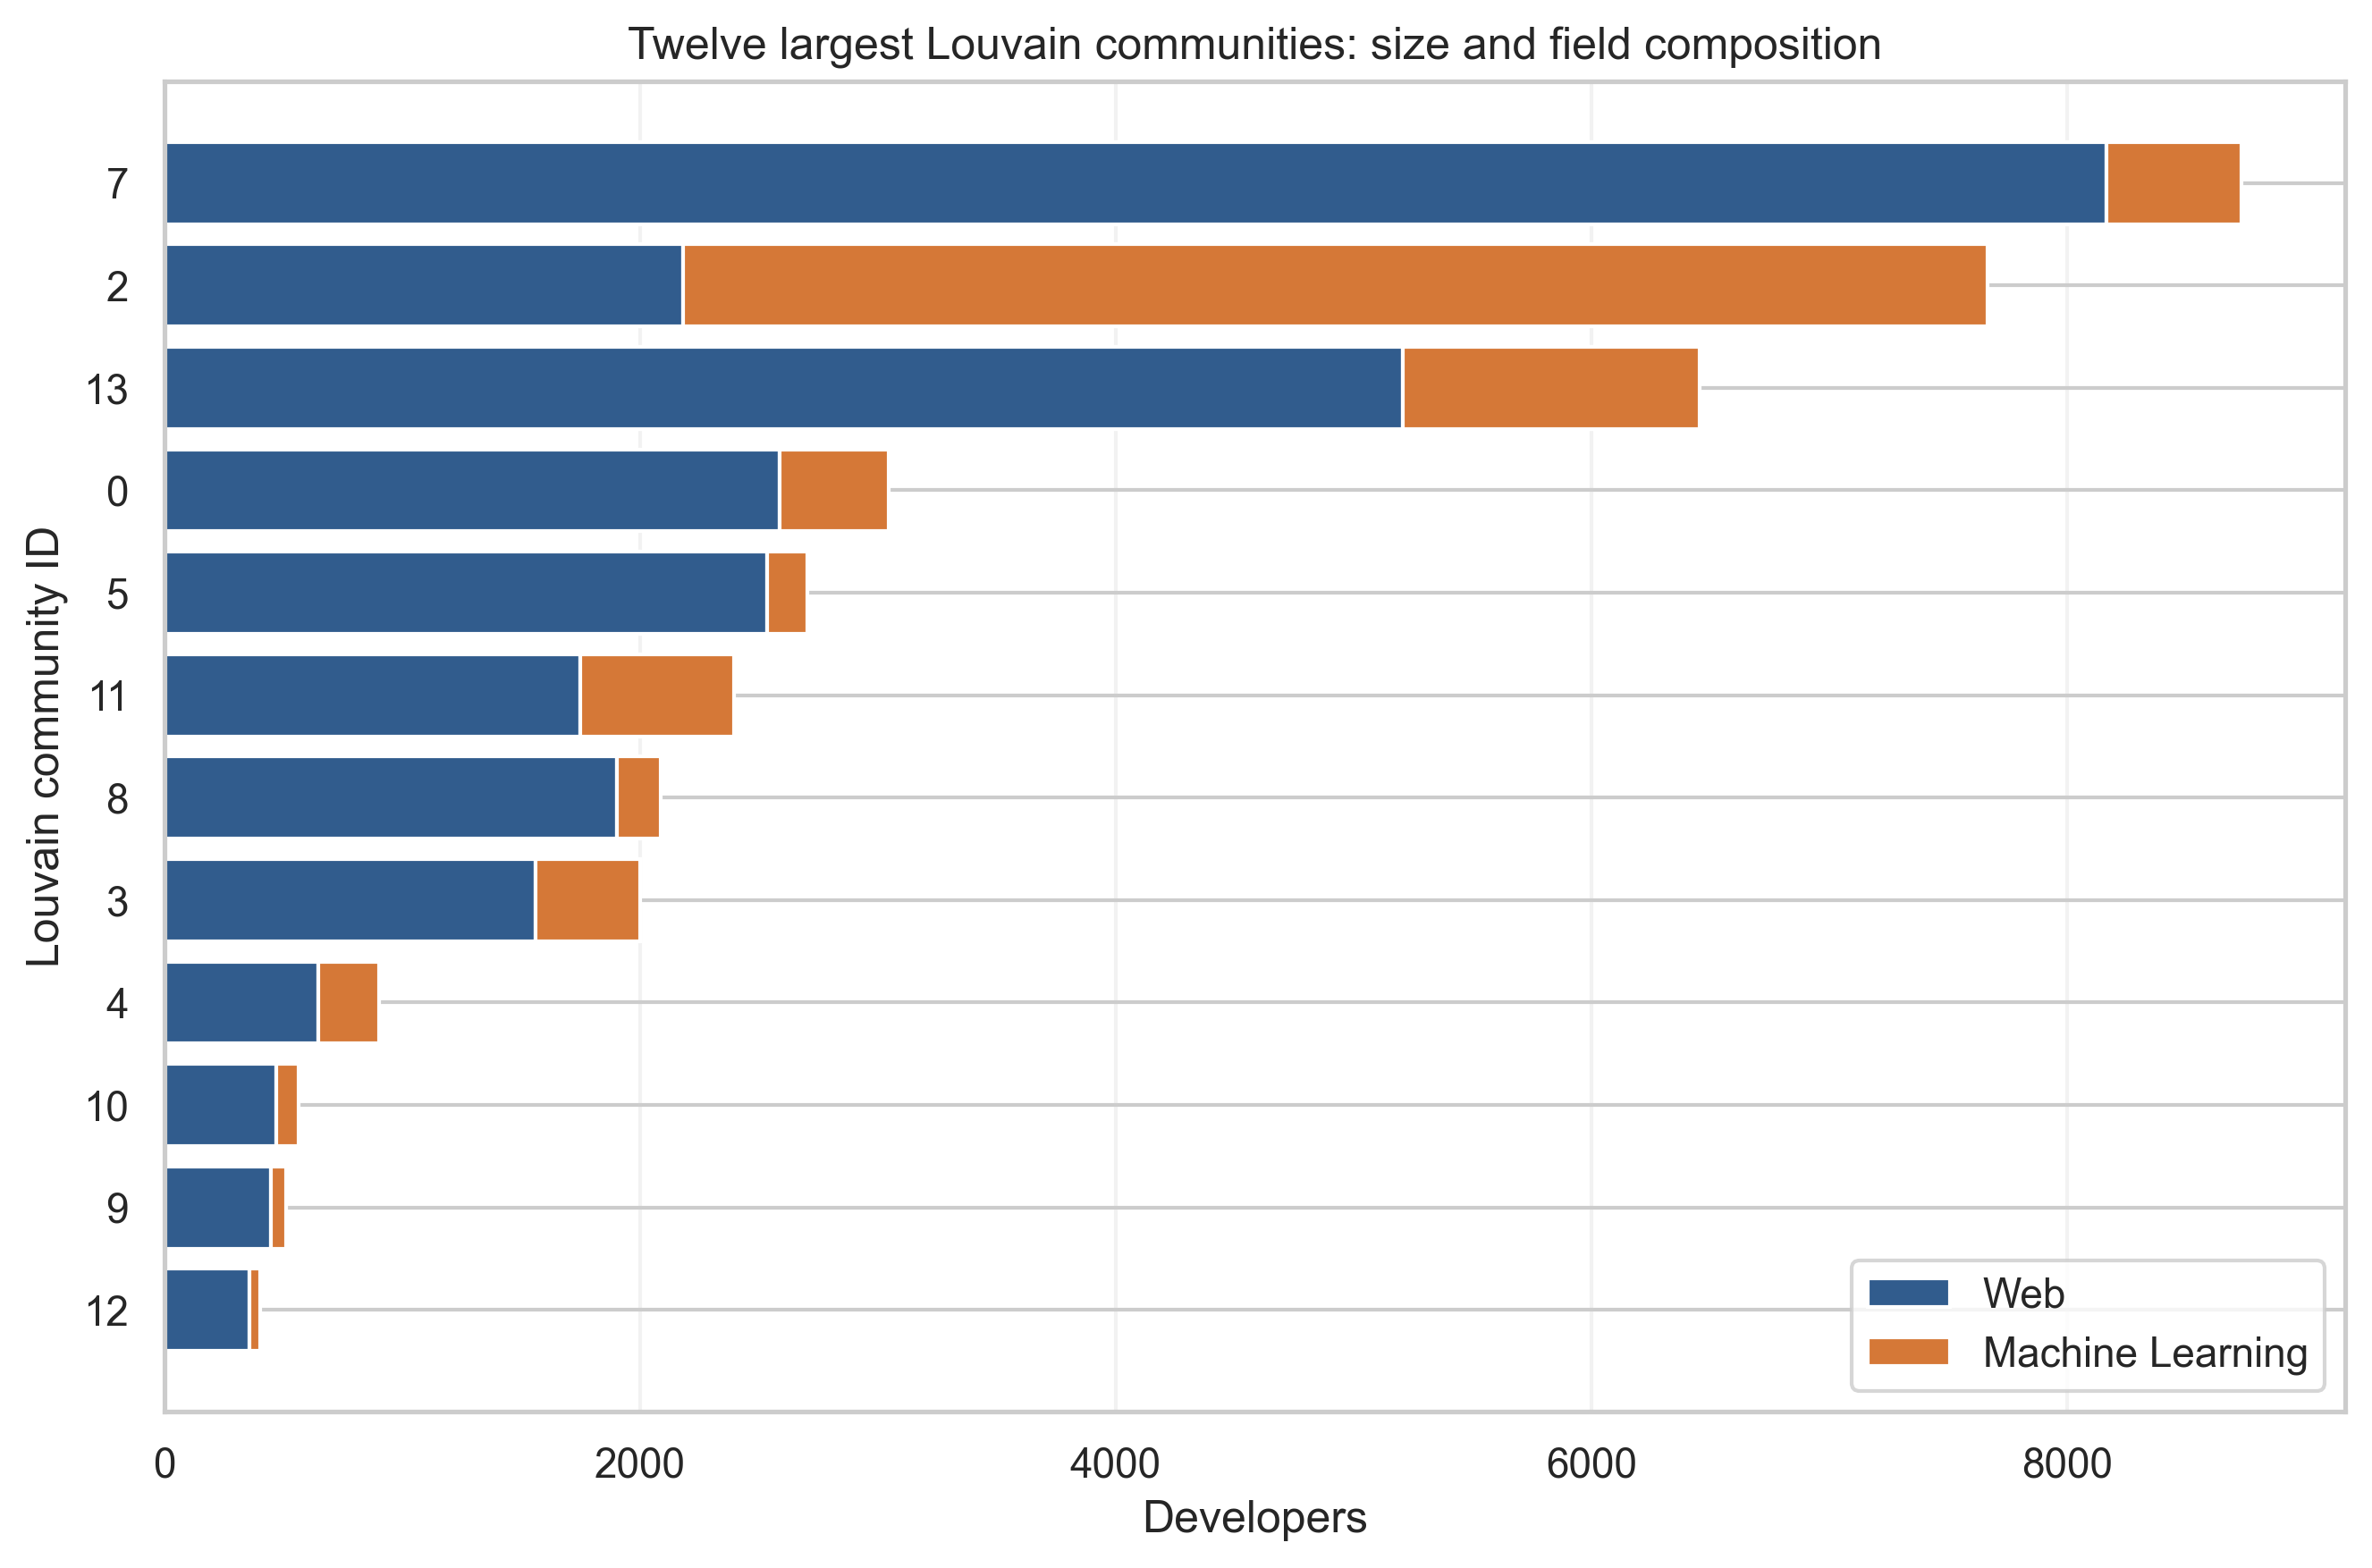

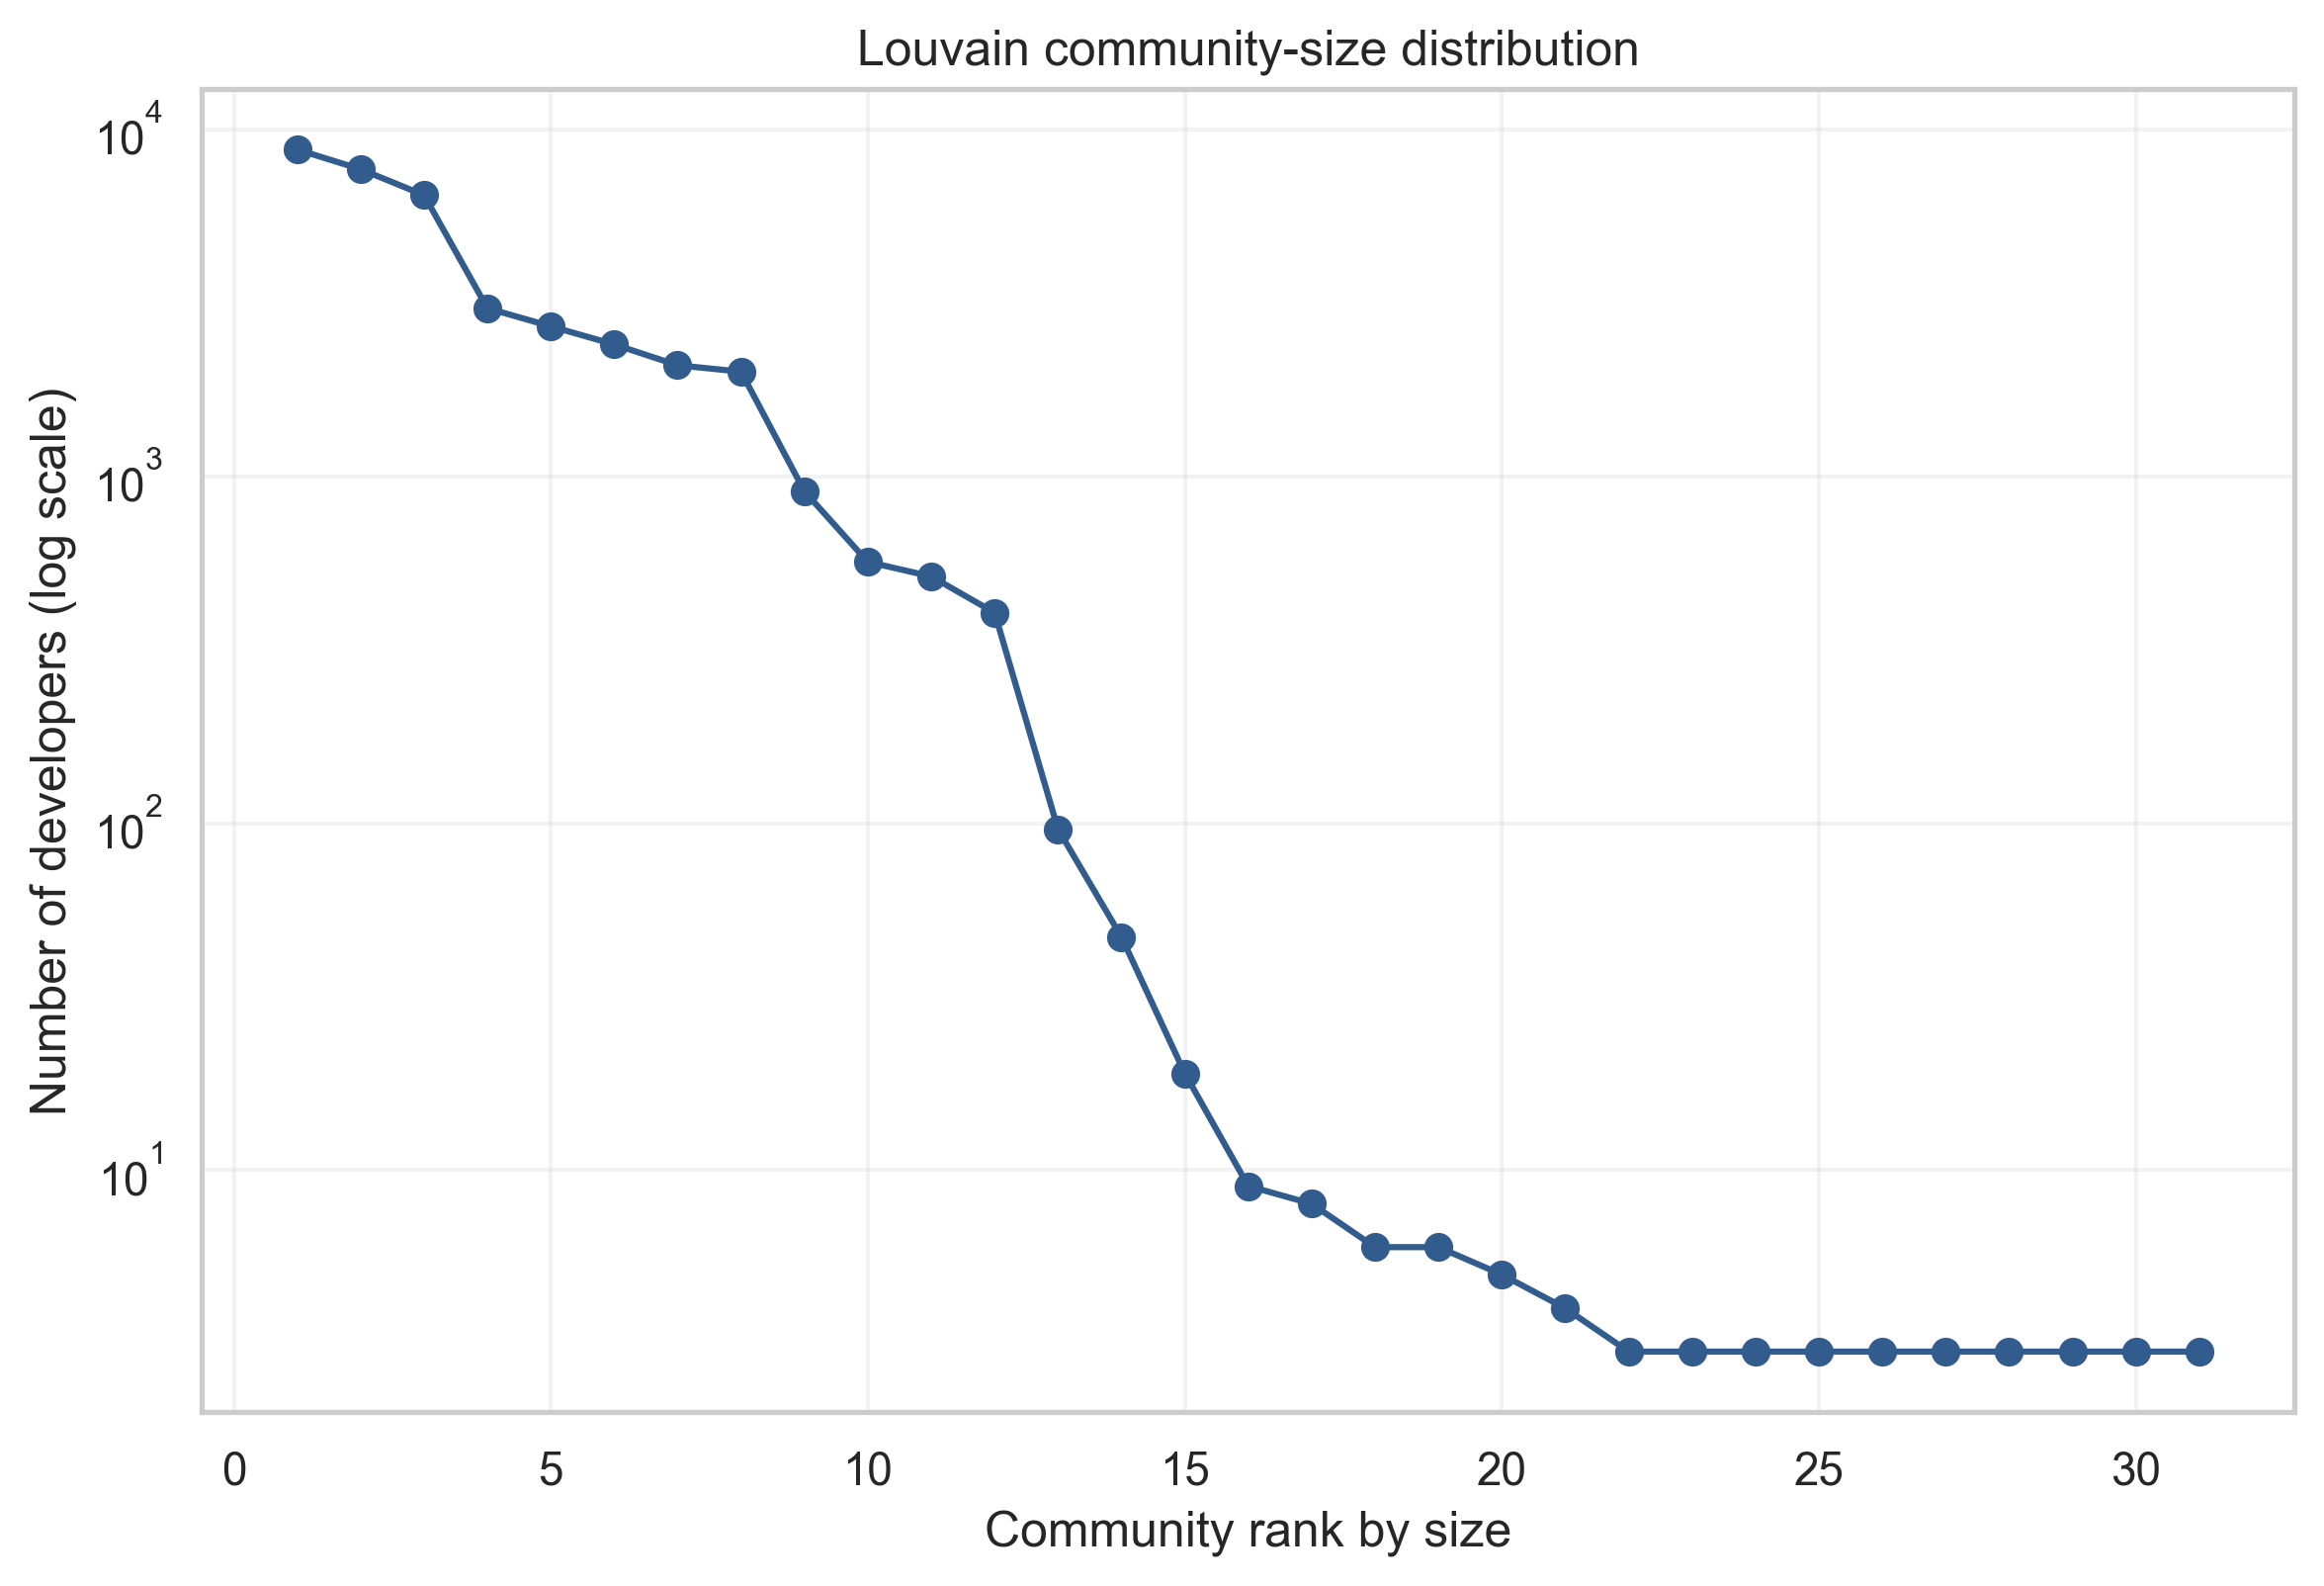

In [5]:
display(pd.read_csv(TABLES_DIR / "community_metrics.csv").round(4))
display(pd.read_csv(TABLES_DIR / "community_summary.csv").head(12).round(3))
display(Image(filename=str(FIGURES_DIR / "community_size_and_composition.png")))
display(Image(filename=str(FIGURES_DIR / "community_size_distribution.png")))

## 6. RQ1 — Node classification without information leakage

Each of five runs uses a stratified 70/30 split. Test labels are excluded from training, neighbor and community feature construction, and threshold calibration. Label-derived community features use training counts only. The workflow below regenerates repeated model results and validation-only threshold analysis.

                                           model  accuracy_mean  accuracy_std  balanced_accuracy_mean  balanced_accuracy_std  precision_mean  precision_std  recall_mean  recall_std  f1_mean   f1_std  macro_f1_mean  macro_f1_std  weighted_f1_mean  weighted_f1_std  roc_auc_mean  roc_auc_std
                               Majority Baseline       0.741645      0.000000                0.500000               0.000000        0.000000       0.000000     0.000000    0.000000 0.000000 0.000000       0.425830      0.000000          0.631629         0.000000      0.500000     0.000000
                               Neighbor Majority       0.818780      0.003222                0.674080               0.005216        0.831198       0.012751     0.374675    0.009899 0.516468 0.010741       0.702481      0.006256          0.792379         0.004110      0.785099     0.005350
       Logistic Regression - Graph Features Only       0.803572      0.004287                0.759211               0.005618      

,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,roc_auc_mean,roc_auc_std
0,Majority Baseline,0.7416,0.0000,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.4258,0.0000,0.6316,0.0000,0.5000,0.0000
1,Neighbor Majority,0.8188,0.0032,0.6741,0.0052,0.8312,0.0128,0.3747,0.0099,0.5165,0.0107,0.7025,0.0063,0.7924,0.0041,0.7851,0.0054
2,Logistic Regression - Graph Features Only,0.8036,0.0043,0.7592,0.0056,0.6095,0.0079,0.6674,0.0097,0.6371,0.0078,0.7512,0.0053,0.8064,0.0042,0.8410,0.0043
3,Logistic Regression - Graph + Community Features,0.8169,0.0035,0.7870,0.0056,0.6257,0.0064,0.7251,0.0125,0.6717,0.0069,0.7724,0.0045,0.8210,0.0034,0.8694,0.0055


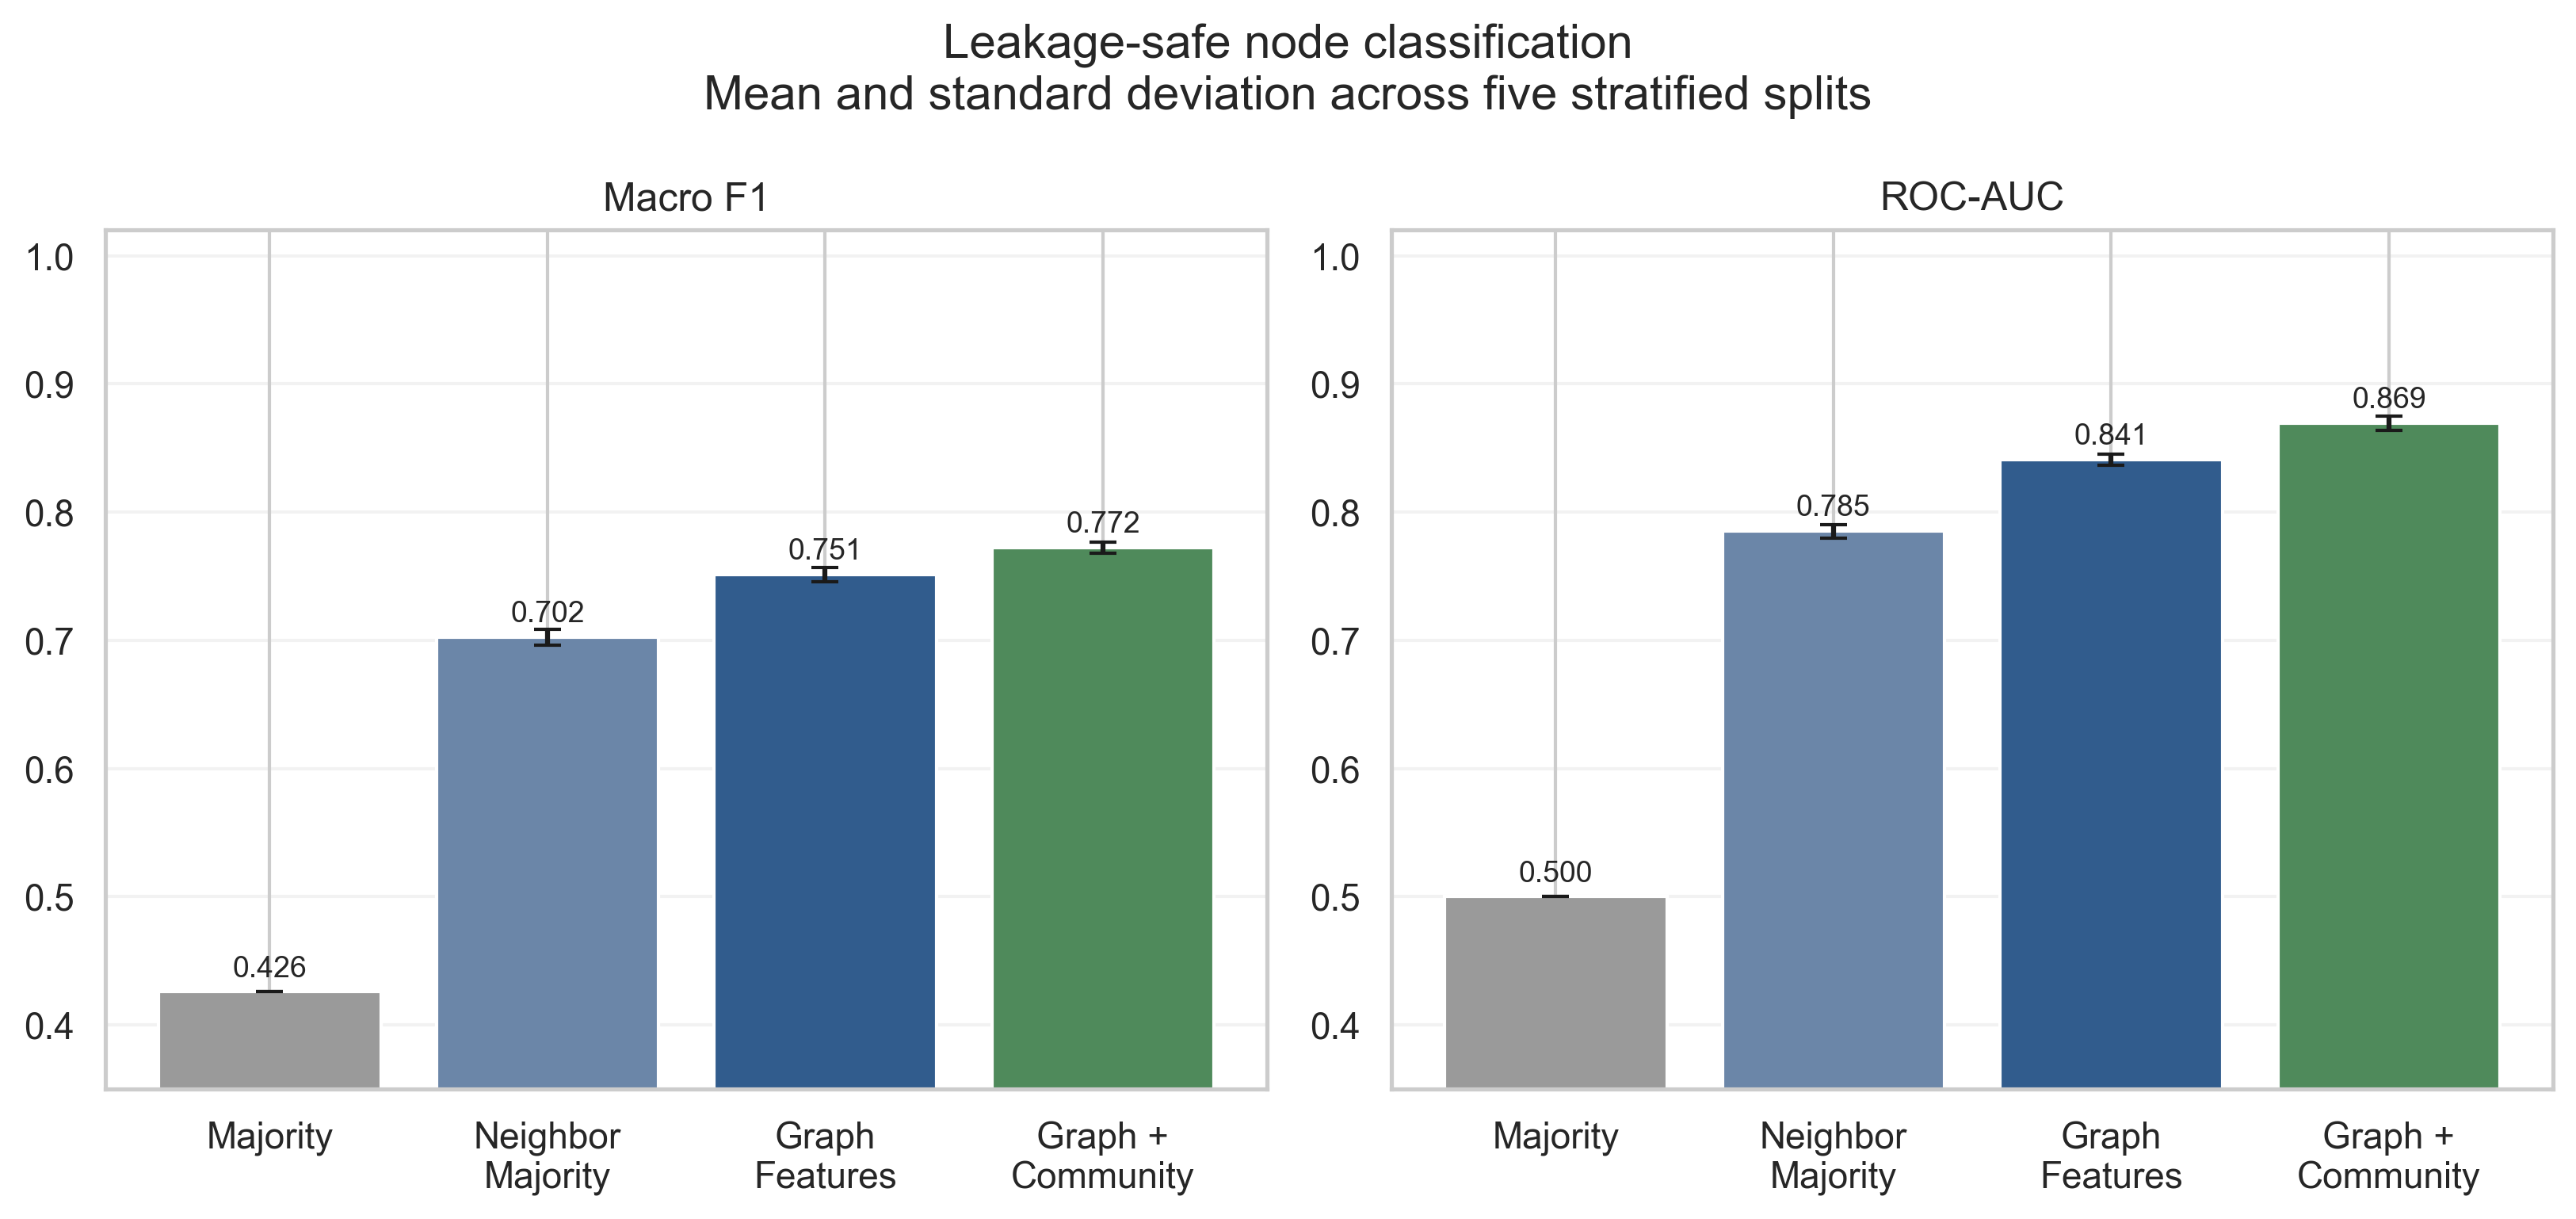

,evaluation_type,selected_threshold_mean,selected_threshold_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,...,f1_mean,f1_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,roc_auc_mean,roc_auc_std,specificity_mean,specificity_std
0,default_threshold_0.5,0.50,0.00,0.8148,0.0026,0.7843,0.0043,0.6221,0.0049,0.7213,...,0.6680,0.0052,0.7698,0.0033,0.8190,0.0025,0.8654,0.0048,0.8474,0.0037
1,tuned_threshold_validation_f1,0.55,0.05,0.8221,0.0076,0.7809,0.0072,0.6458,0.0250,0.6958,...,0.6689,0.0065,0.7736,0.0050,0.8242,0.0056,0.8654,0.0048,0.8661,0.0201


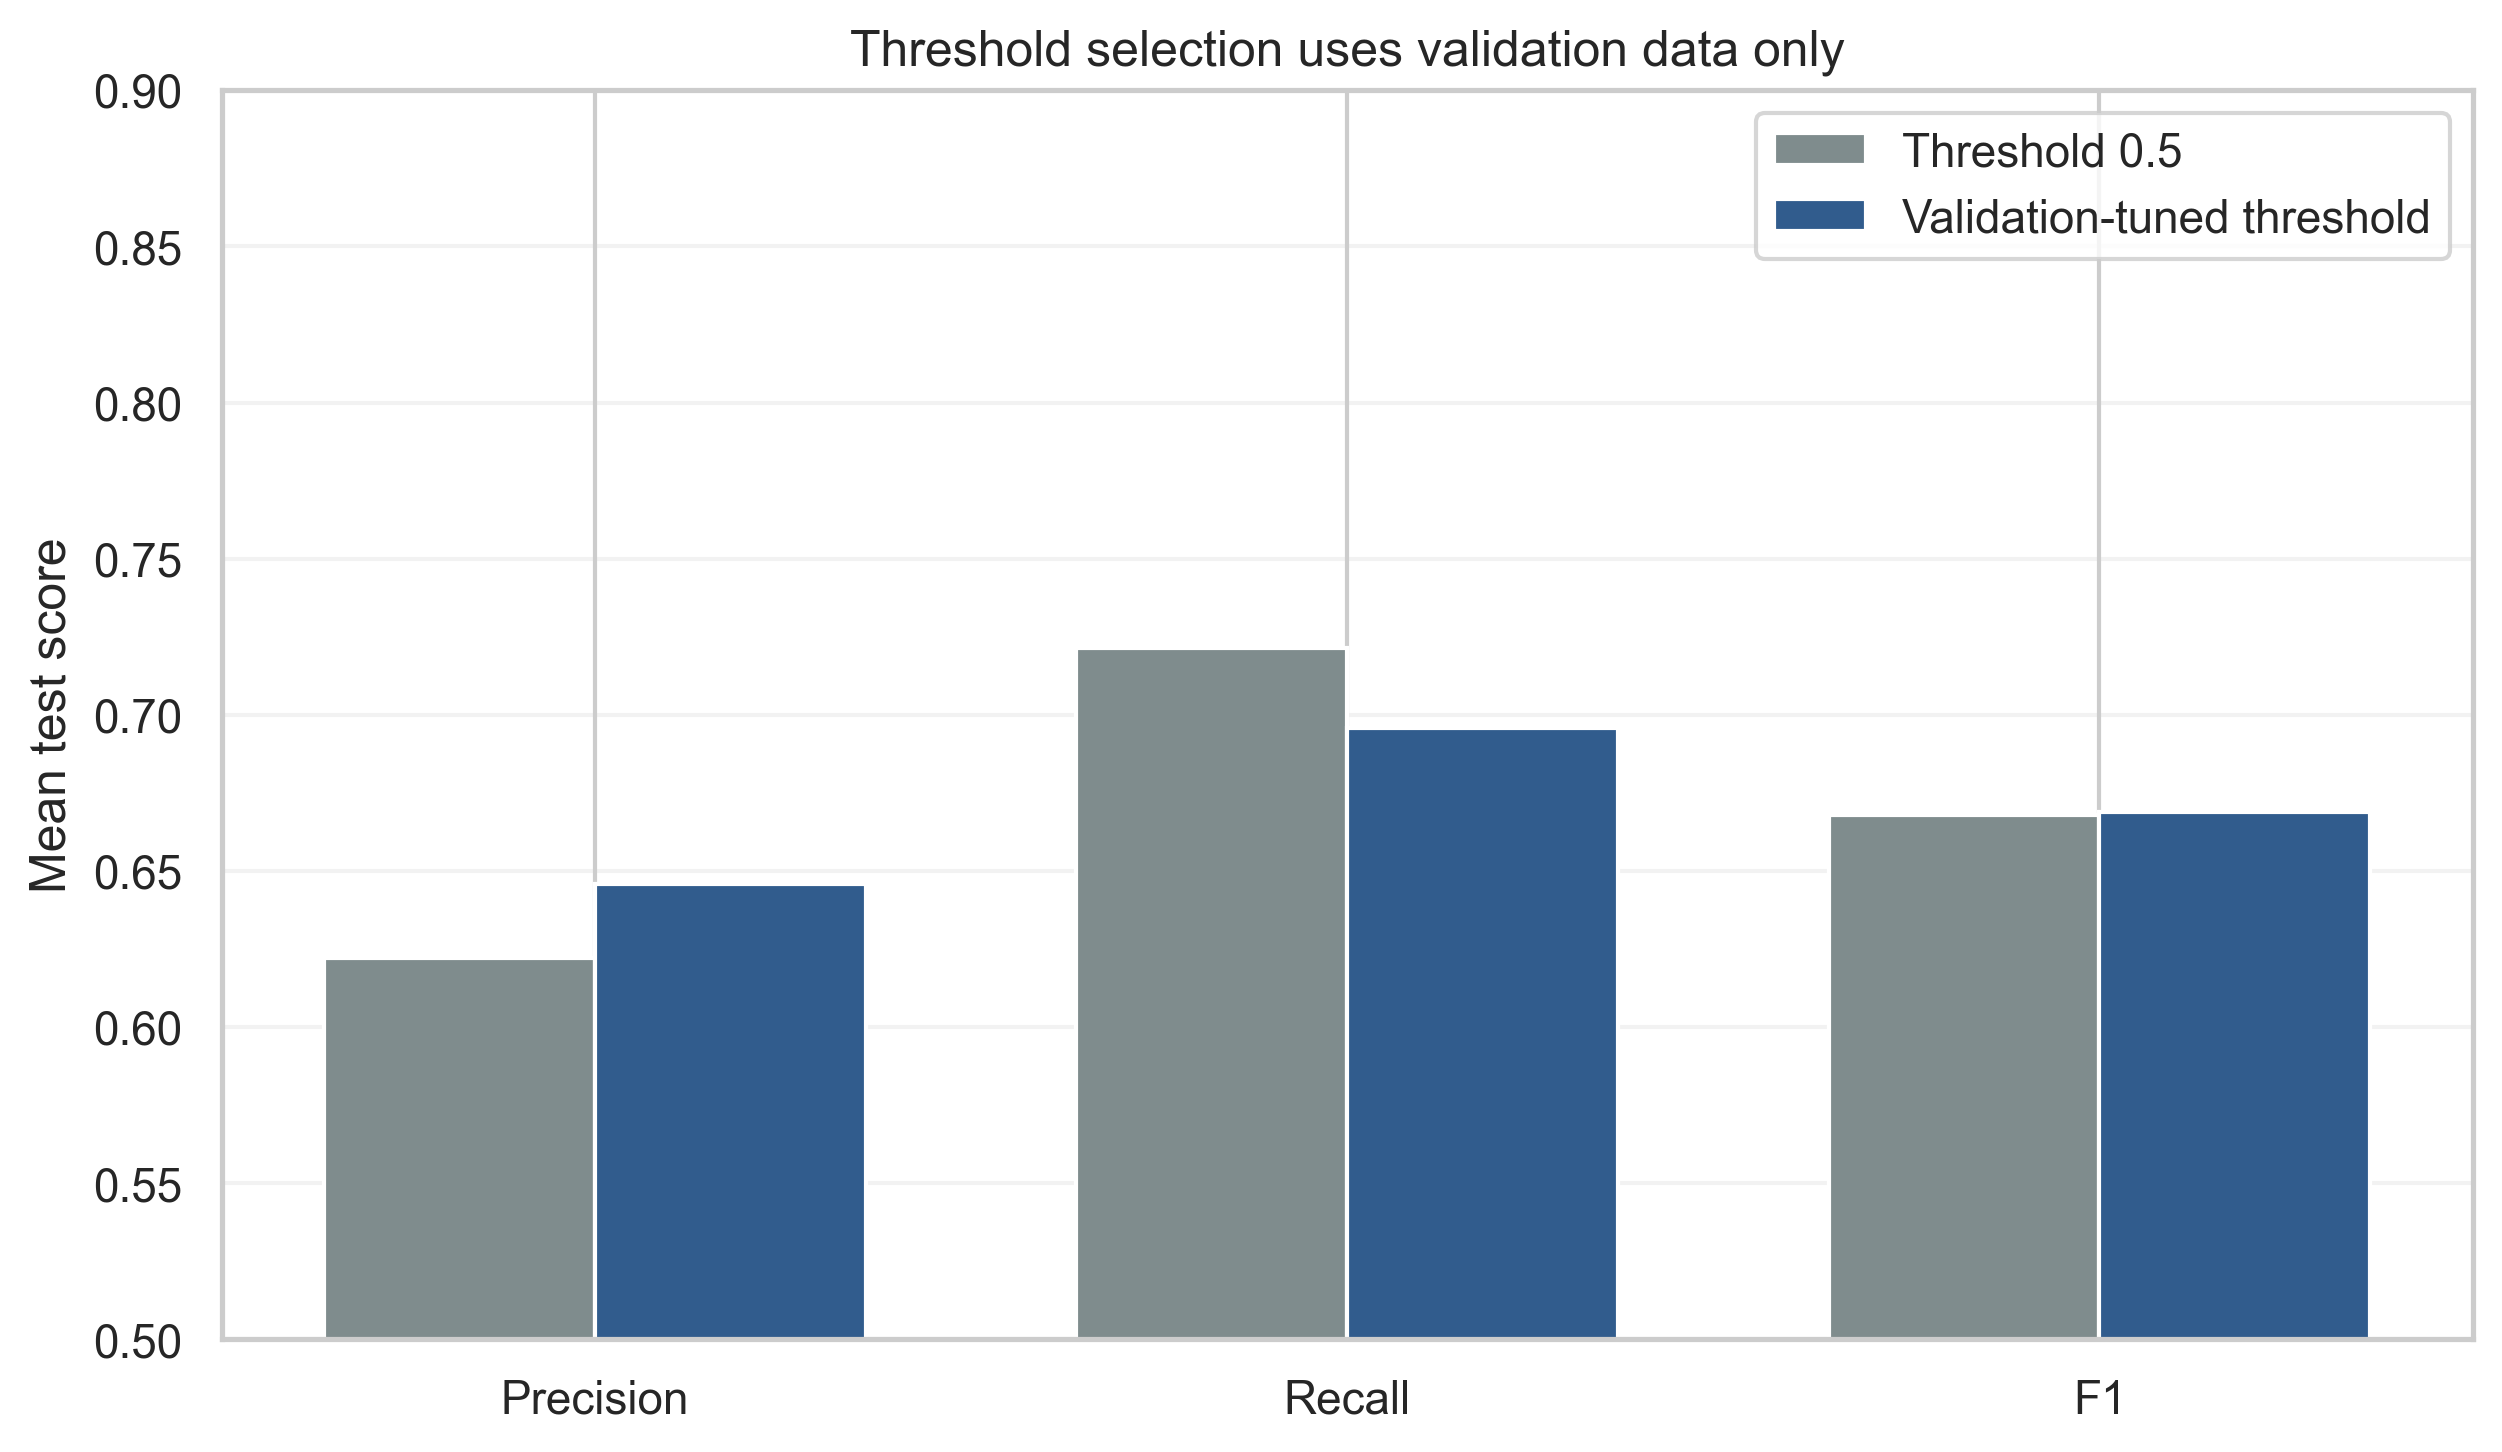

In [6]:
from run_classification import main as run_classification
run_classification()
display(pd.read_csv(TABLES_DIR / "classification_summary.csv").round(4))
display(Image(filename=str(FIGURES_DIR / "classification_comparison.png")))
display(pd.read_csv(TABLES_DIR / "threshold_tuning_summary.csv").round(4))
display(Image(filename=str(FIGURES_DIR / "threshold_tradeoff.png")))

### RQ1 results

| Model | Mean Macro F1 | SD Macro F1 | Mean ROC-AUC | SD ROC-AUC |
|---|---:|---:|---:|---:|
| Majority Baseline | 0.426 | 0.000 | 0.500 | 0.000 |
| Neighbor Majority | 0.702 | 0.006 | 0.785 | 0.005 |
| Logistic Regression — Graph Features Only | 0.751 | 0.005 | 0.841 | 0.004 |
| Logistic Regression — Graph + Community Features | 0.772 | 0.004 | 0.869 | 0.005 |

Graph + Community is the strongest handcrafted model at mean ROC-AUC 0.869. Its advantage over neighbor voting shows the cumulative value of centrality and community features. Validation-only threshold selection changes the Precision-Recall balance but not ROC-AUC.

## 7. RQ2 — Ablation: network, content, and hybrid information

All three information sources use the same classifier, seeds, splits, and metrics. Performance differences can therefore be attributed to representation choice rather than a different evaluation protocol.

Loaded content features: 37700 nodes, 4005 feature dims


Louvain: 31 communities, modularity=0.4534
[run 1/5] random_state=42


    Logistic Regression - Content Features Only: F1=0.6937 MacroF1=0.7863 ROC-AUC=0.8860
    Logistic Regression - Network Only (Graph + Community): F1=0.6671 MacroF1=0.7693 ROC-AUC=0.8675
    Logistic Regression - Hybrid (Network + Content): F1=0.7034 MacroF1=0.7934 ROC-AUC=0.8949
[run 2/5] random_state=7


    Logistic Regression - Content Features Only: F1=0.7079 MacroF1=0.7958 ROC-AUC=0.8934
    Logistic Regression - Network Only (Graph + Community): F1=0.6790 MacroF1=0.7759 ROC-AUC=0.8732
    Logistic Regression - Hybrid (Network + Content): F1=0.7160 MacroF1=0.8020 ROC-AUC=0.9012
[run 3/5] random_state=21


    Logistic Regression - Content Features Only: F1=0.6954 MacroF1=0.7880 ROC-AUC=0.8857
    Logistic Regression - Network Only (Graph + Community): F1=0.6685 MacroF1=0.7707 ROC-AUC=0.8665
    Logistic Regression - Hybrid (Network + Content): F1=0.7013 MacroF1=0.7925 ROC-AUC=0.8941
[run 4/5] random_state=84


    Logistic Regression - Content Features Only: F1=0.7030 MacroF1=0.7925 ROC-AUC=0.8934
    Logistic Regression - Network Only (Graph + Community): F1=0.6792 MacroF1=0.7782 ROC-AUC=0.8768
    Logistic Regression - Hybrid (Network + Content): F1=0.7166 MacroF1=0.8022 ROC-AUC=0.9027
[run 5/5] random_state=123


    Logistic Regression - Content Features Only: F1=0.6940 MacroF1=0.7864 ROC-AUC=0.8851
    Logistic Regression - Network Only (Graph + Community): F1=0.6647 MacroF1=0.7678 ROC-AUC=0.8631
    Logistic Regression - Hybrid (Network + Content): F1=0.7053 MacroF1=0.7951 ROC-AUC=0.8947
Saved: C:\Users\Jimi\Desktop\github-social-network\outputs\tables\ablation_model_results.csv
Saved: C:\Users\Jimi\Desktop\github-social-network\outputs\tables\ablation_model_results_summary.csv


Saved: C:\Users\Jimi\Desktop\github-social-network\outputs\figures\ablation_f1_auc_comparison.png

=== Summary (mean over splits) ===
                                                 model  f1_mean  macro_f1_mean  roc_auc_mean  recall_mean  precision_mean
           Logistic Regression - Content Features Only 0.698807       0.789794      0.888715     0.767077        0.641710
      Logistic Regression - Hybrid (Network + Content) 0.708514       0.797029      0.897519     0.773306        0.653761
Logistic Regression - Network Only (Graph + Community) 0.671694       0.772363      0.869394     0.725120        0.625680


,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,roc_auc_mean,roc_auc_std
0,Logistic Regression - Content Features Only,0.8292,0.0032,0.8089,0.0051,0.6417,0.0046,0.7671,0.0095,0.6988,0.0063,0.7898,0.0042,0.8338,0.0032,0.8887,0.0043
1,Logistic Regression - Hybrid (Network + Content),0.8356,0.0034,0.8153,0.0060,0.6538,0.0046,0.7733,0.0114,0.7085,0.0073,0.7970,0.0047,0.8398,0.0035,0.8975,0.0041
2,Logistic Regression - Network Only (Graph + Co...,0.8169,0.0035,0.7870,0.0056,0.6257,0.0064,0.7251,0.0125,0.6717,0.0069,0.7724,0.0045,0.8210,0.0034,0.8694,0.0055


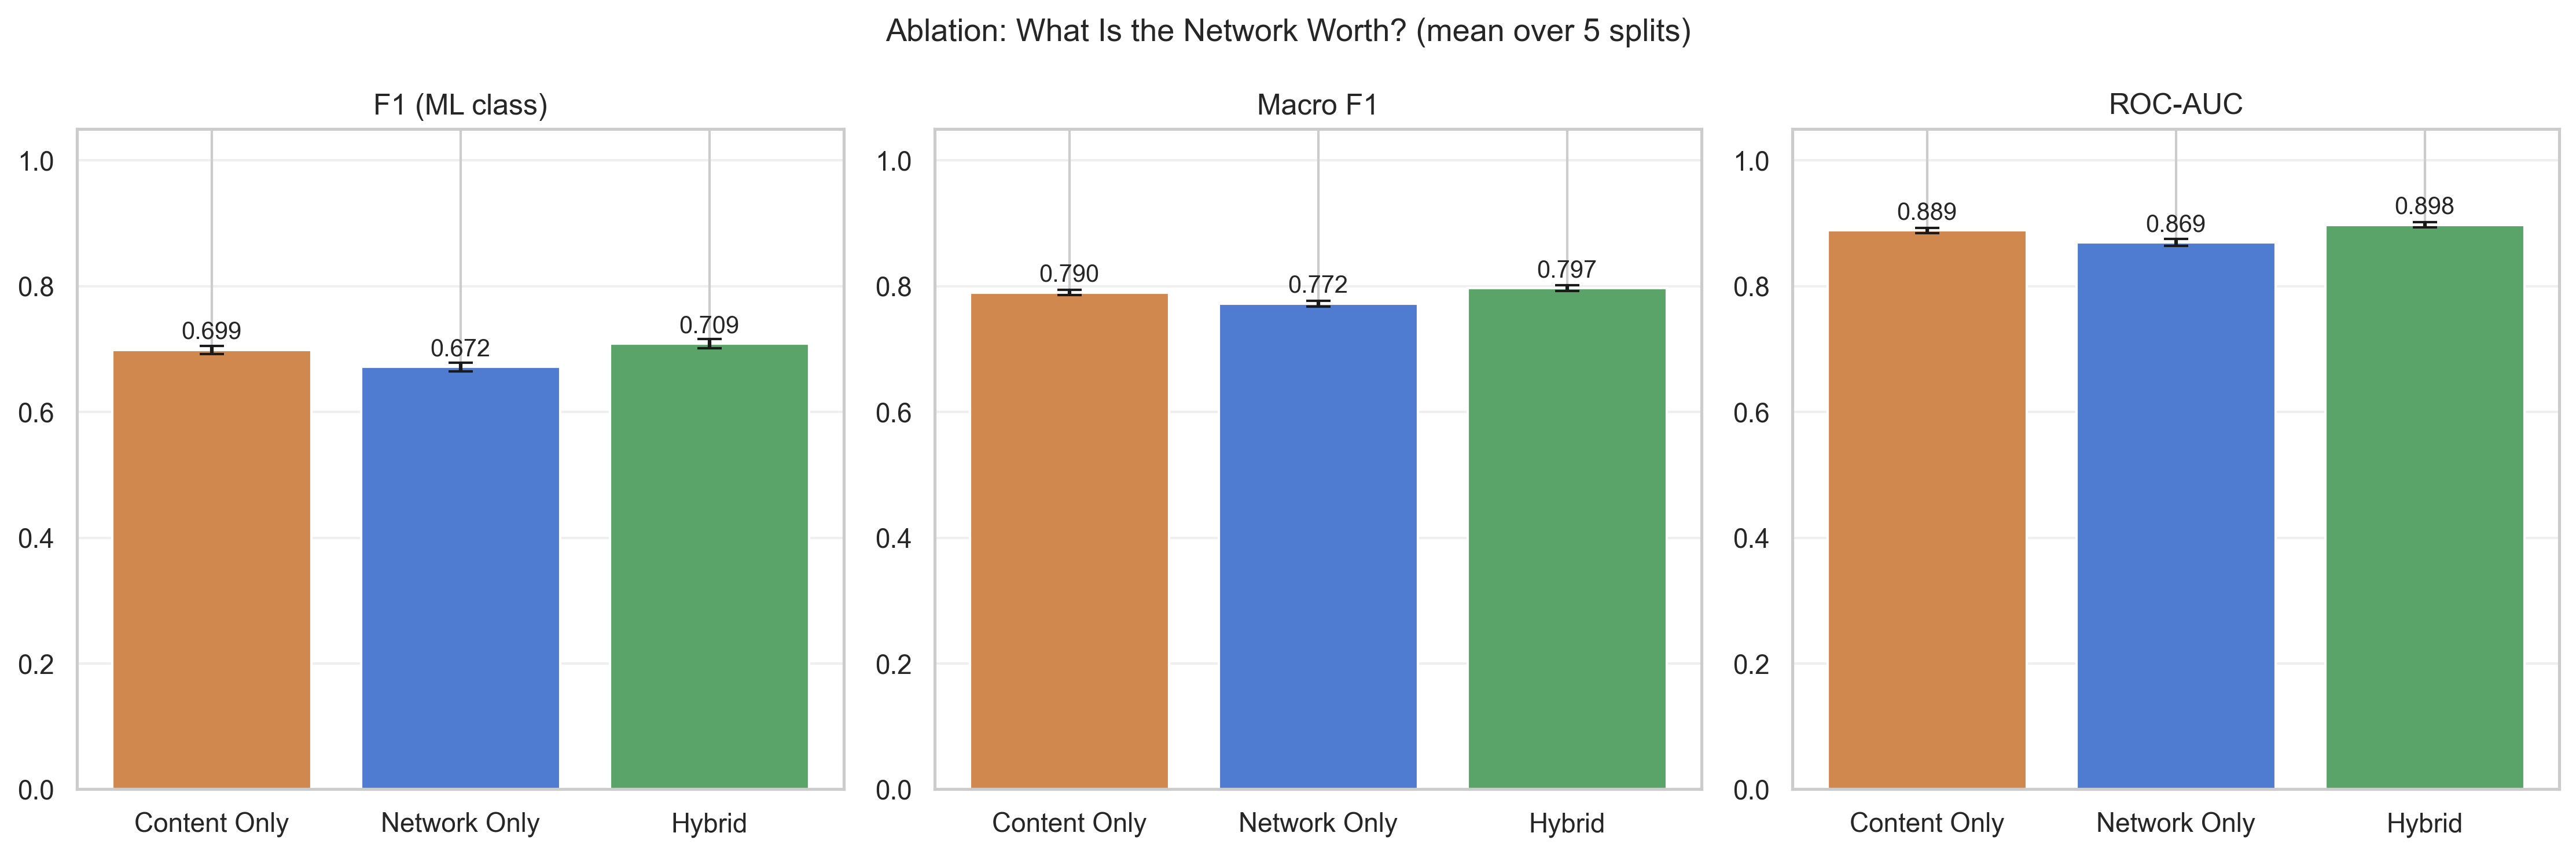

In [7]:
from run_ablation import main as run_ablation
run_ablation()
display(pd.read_csv(TABLES_DIR / "ablation_model_results_summary.csv").round(4))
display(Image(filename=str(FIGURES_DIR / "ablation_f1_auc_comparison.png")))

### RQ2 results

| Information source | Macro F1 | ROC-AUC | AUC SD |
|---|---:|---:|---:|
| Content Features Only | 0.790 | 0.889 | 0.004 |
| Hybrid Network + Content | 0.797 | 0.898 | 0.004 |
| Network Only, Graph + Community | 0.772 | 0.869 | 0.005 |

Content is a strong reference and exceeds the handcrafted network representation alone. The hybrid improves the mean, indicating complementary information. This is predictive evidence under the tested splits, not proof that either source causes the label.

## 8. Learned representations: DeepWalk and Node2Vec

Both representations are learned without labels or content using the same budget: 3 walks per node, walk length 40, 64 dimensions, window 5, and 5 epochs. Node2Vec uses p=1 and q=2 for a modest local-neighborhood bias. Each representation is tested alone and together with handcrafted graph features.

DeepWalk trained in 89.9s


Node2Vec trained in 313.6s


                                             model  accuracy_mean  accuracy_std  balanced_accuracy_mean  balanced_accuracy_std  precision_mean  precision_std  recall_mean  recall_std  f1_mean   f1_std  macro_f1_mean  macro_f1_std  weighted_f1_mean  weighted_f1_std  roc_auc_mean  roc_auc_std
                    Logistic Regression - Node2Vec       0.820088      0.004381                0.807901               0.004737        0.620374       0.007667     0.782683    0.007525 0.692120 0.006515       0.782514      0.004844          0.826201         0.004078      0.890272     0.004724
                    Logistic Regression - DeepWalk       0.820495      0.003372                0.808599               0.005520        0.620835       0.004703     0.783984    0.010407 0.692926 0.006648       0.783052      0.004421          0.826610         0.003362      0.890676     0.004490
Logistic Regression - Node2Vec + Graph + Community       0.827639      0.004484                0.815311               0.0053

,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,roc_auc_mean,roc_auc_std
0,Logistic Regression - Node2Vec,0.8201,0.0044,0.8079,0.0047,0.6204,0.0077,0.7827,0.0075,0.6921,0.0065,0.7825,0.0048,0.8262,0.0041,0.8903,0.0047
1,Logistic Regression - DeepWalk,0.8205,0.0034,0.8086,0.0055,0.6208,0.0047,0.7840,0.0104,0.6929,0.0066,0.7831,0.0044,0.8266,0.0034,0.8907,0.0045
2,Logistic Regression - Node2Vec + Graph + Commu...,0.8276,0.0045,0.8153,0.0054,0.6336,0.0083,0.7898,0.0108,0.7031,0.0070,0.7908,0.0050,0.8332,0.0042,0.8990,0.0048
3,Logistic Regression - DeepWalk + Graph + Commu...,0.8277,0.0031,0.8156,0.0051,0.6335,0.0050,0.7906,0.0106,0.7034,0.0060,0.7910,0.0040,0.8333,0.0031,0.8996,0.0047


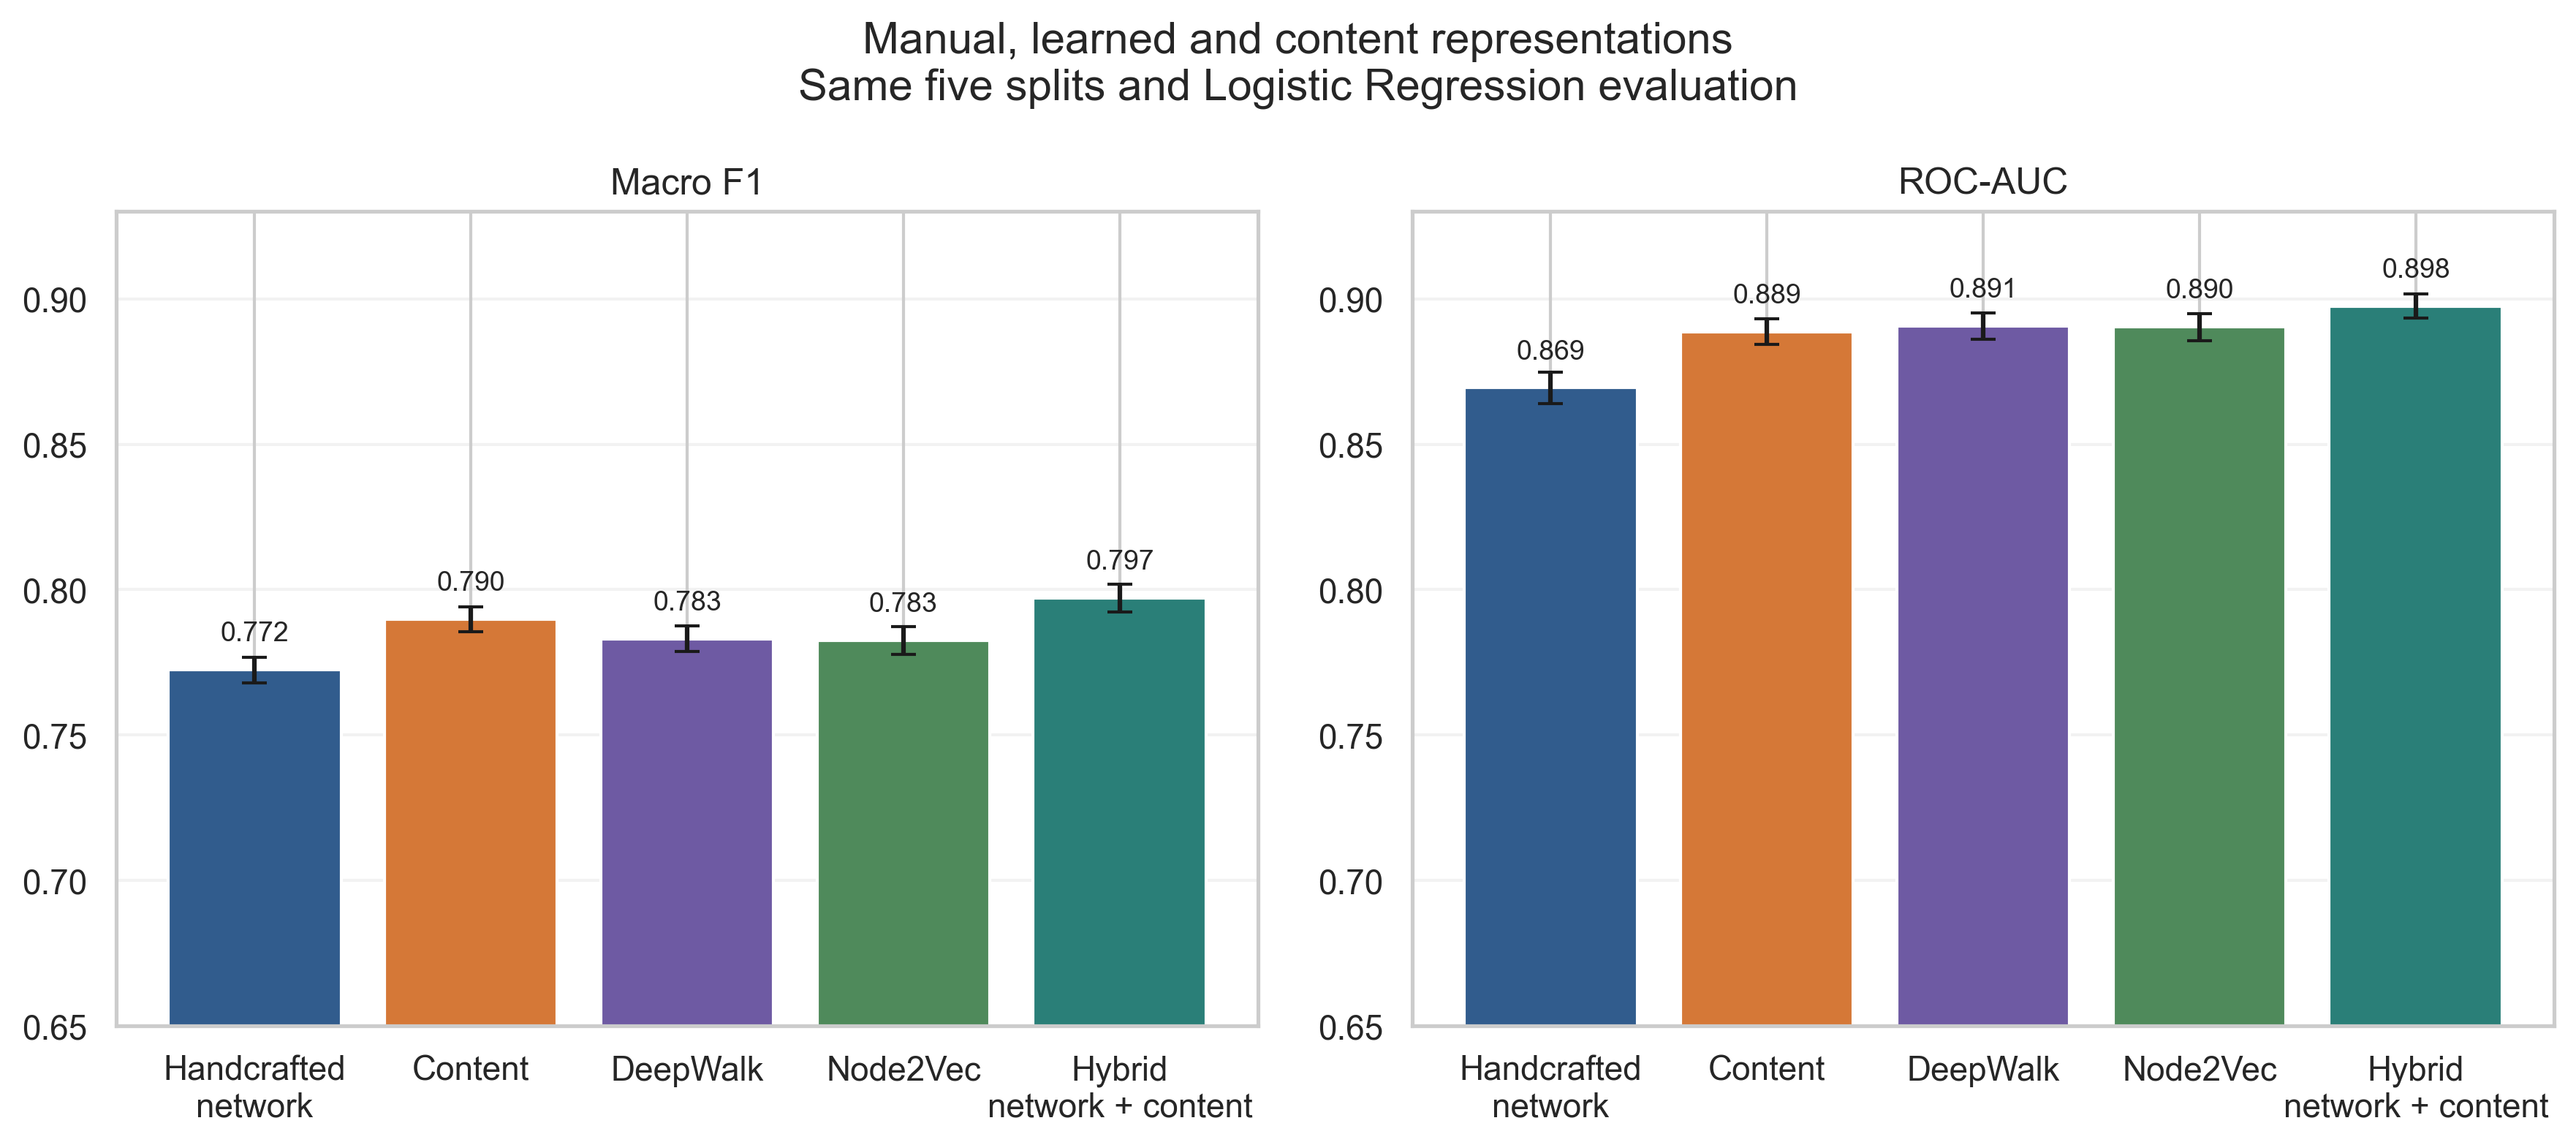

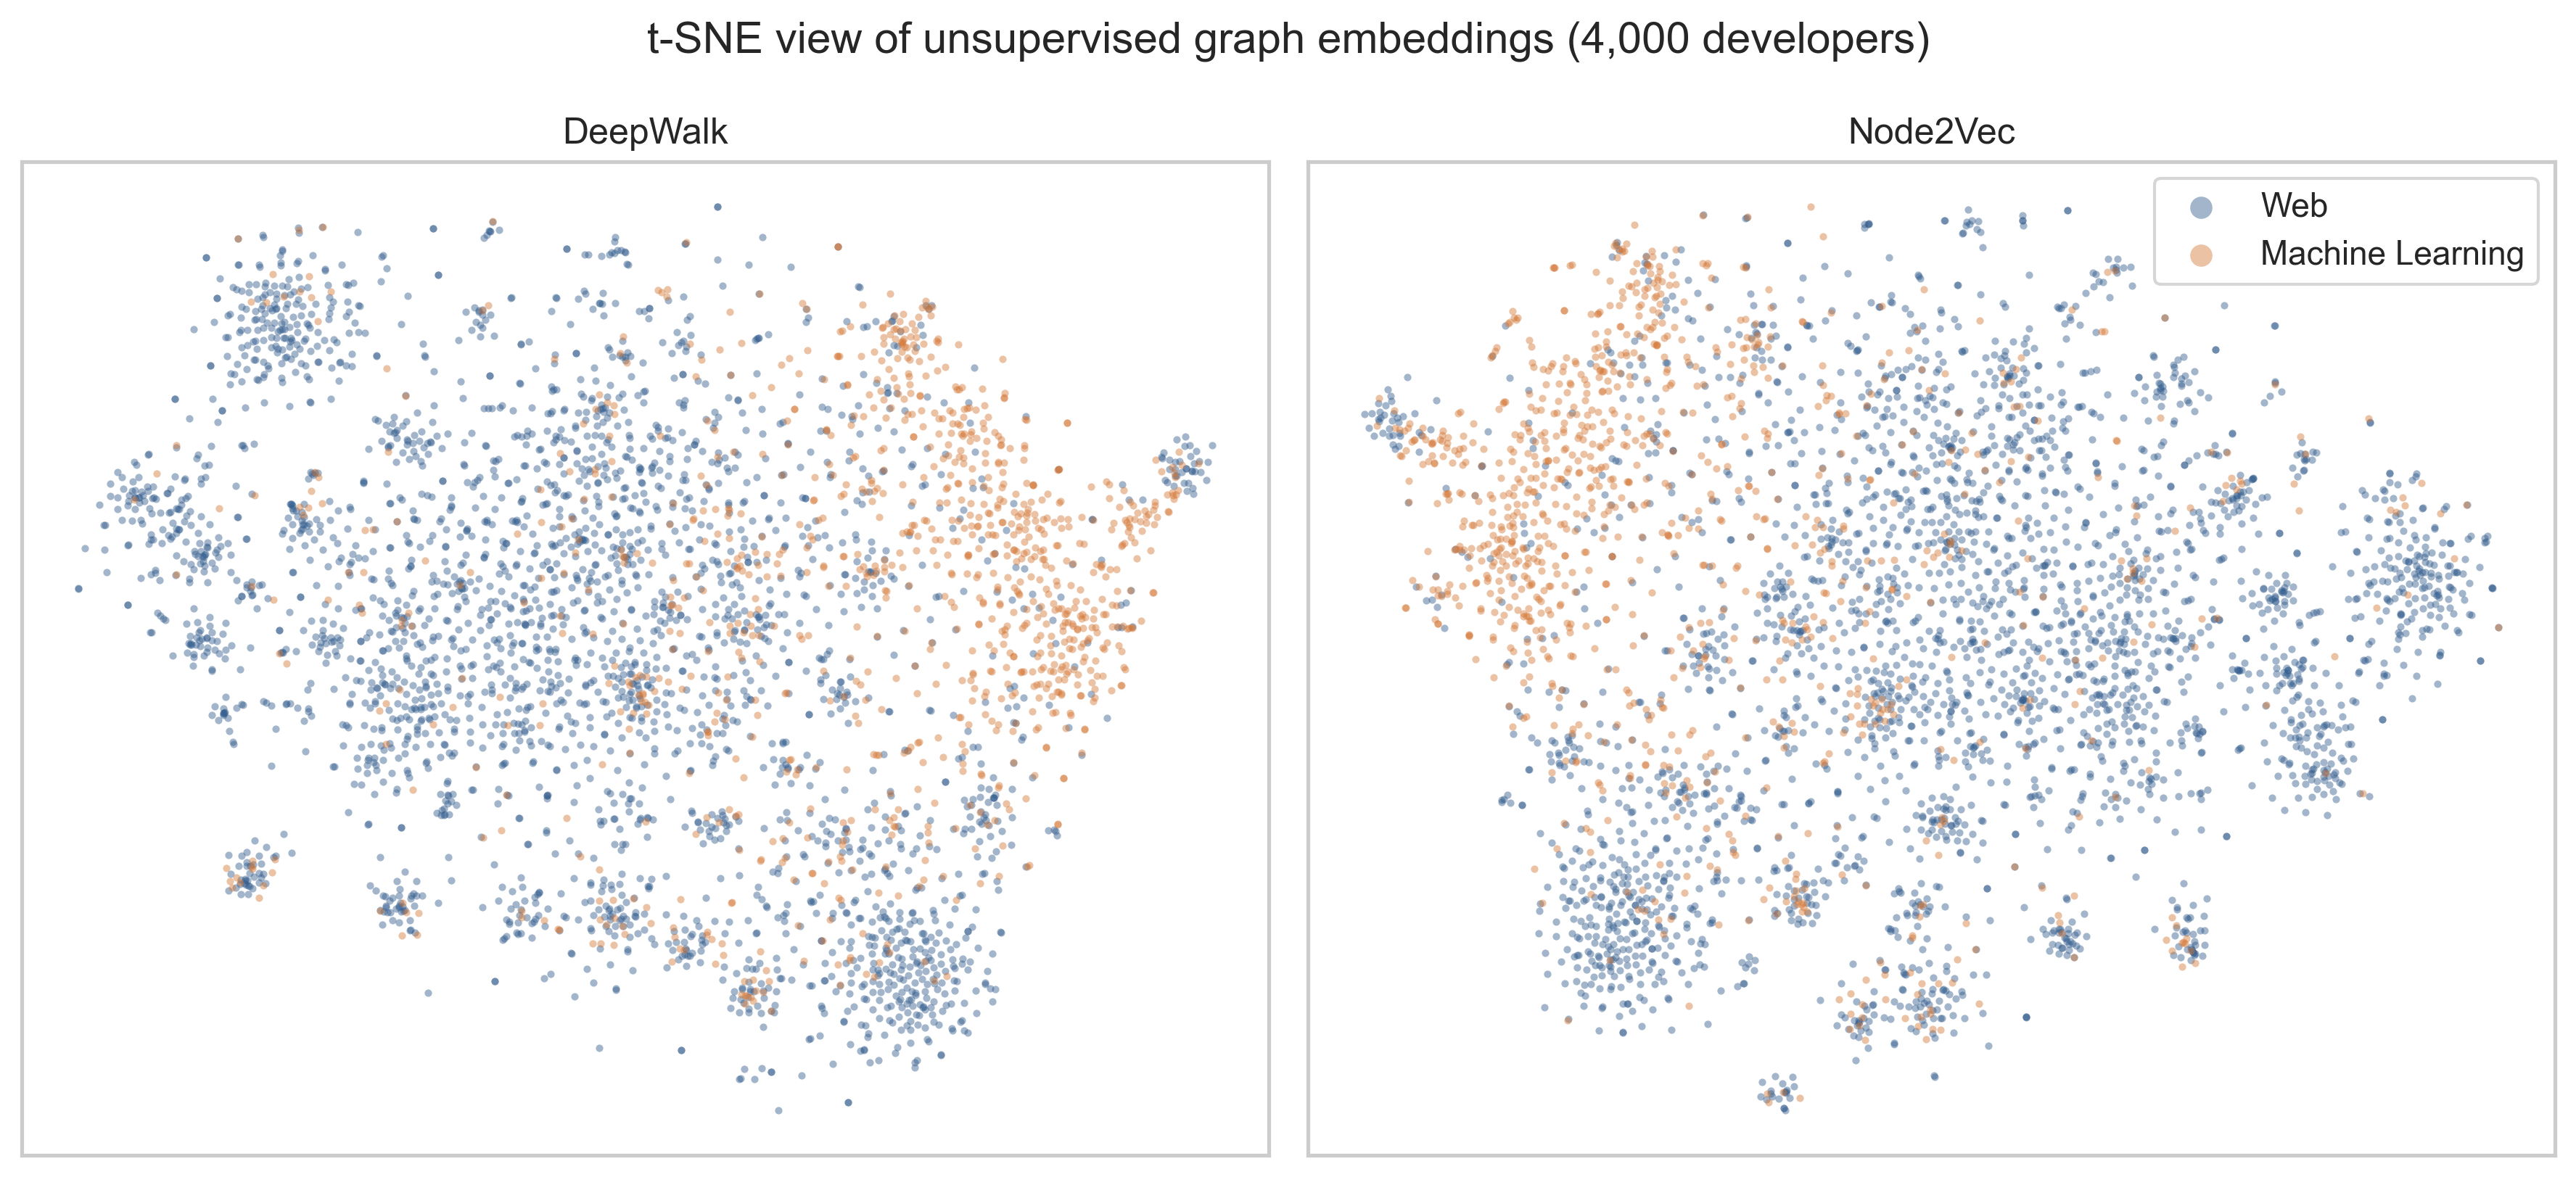

In [8]:
from run_embeddings import main as run_embeddings
run_embeddings()
display(pd.read_csv(TABLES_DIR / "embedding_classification_summary.csv").round(4))
display(Image(filename=str(FIGURES_DIR / "representation_comparison.png")))
display(Image(filename=str(FIGURES_DIR / "embedding_tsne.png")))

### Representation comparison

| Model | Macro F1 | ROC-AUC | AUC SD |
|---|---:|---:|---:|
| Node2Vec | 0.783 | 0.890 | 0.005 |
| DeepWalk | 0.783 | 0.891 | 0.004 |
| Node2Vec + Graph + Community | 0.791 | 0.899 | 0.005 |
| DeepWalk + Graph + Community | 0.791 | 0.900 | 0.005 |

DeepWalk alone reaches ROC-AUC 0.891 and Node2Vec 0.890. The comparison shows how effectively random-walk contexts compress useful network structure. Similar performance does not prove representation equivalence; it applies only to the tested data, hyperparameters, and classifier.

## 9. RQ3 — Edge reconstruction while preserving connectivity

For each seed, a spanning tree is protected and test positives are sampled only from non-tree edges. After removal, the workflow explicitly checks `nx.is_connected(G_train)` and verifies that no node is isolated. Connectivity is necessary for path-based measures, Louvain, and graph walks.

Negative examples are true non-edges of the complete graph and match the positive count within Web-Web, ML-ML, and Web-ML. Same-field and cross-field results therefore use the same sampling rule.

[edge split 1/5] seed=42


  hidden=28,900; train_connected=True; isolated=0


  completed in 110.9s
[edge split 2/5] seed=7


  hidden=28,900; train_connected=True; isolated=0


  completed in 107.1s
[edge split 3/5] seed=21


...

  hidden=28,900; train_connected=True; isolated=0


  completed in 109.8s



Overall reconstruction summary:
              heuristic  roc_auc_mean  roc_auc_std  average_precision_mean  average_precision_std
            Adamic-Adar      0.860359     0.002658                0.869723               0.002457
       Common Neighbors      0.852613     0.002758                0.848178               0.002769
               DeepWalk      0.896513     0.002614                0.906930               0.002277
                Jaccard      0.796064     0.003765                0.712517               0.005696
               Node2Vec      0.900278     0.002775                0.910573               0.002363
Preferential Attachment      0.923876     0.001096                0.931209               0.001347
         Same Community      0.704073     0.004271                0.656732               0.003613

Same-field minus cross-field gaps:
              heuristic  roc_auc_same_minus_cross  average_precision_same_minus_cross
            Adamic-Adar                  0.036923            

,seed,requested_test_fraction,actual_test_fraction,protected_tree_edges,hidden_positive_edges,negative_pairs,train_nodes,train_edges,train_connected,isolated_nodes,positive_web_web,negative_web_web,positive_ml_ml,negative_ml_ml,positive_web_ml,negative_web_ml,run
0,42,0.1,0.099999,37699,28900,28900,37700,260103,True,0,22727,22727,1907,1907,4266,4266,1
1,7,0.1,0.099999,37699,28900,28900,37700,260103,True,0,22876,22876,1828,1828,4196,4196,2
2,21,0.1,0.099999,37699,28900,28900,37700,260103,True,0,22838,22838,1788,1788,4274,4274,3
3,84,0.1,0.099999,37699,28900,28900,37700,260103,True,0,22678,22678,1983,1983,4239,4239,4
4,123,0.1,0.099999,37699,28900,28900,37700,260103,True,0,22693,22693,1875,1875,4332,4332,5


,heuristic,n_positive_mean,n_negative_mean,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std
0,Adamic-Adar,28900.0,28900.0,0.8604,0.0027,0.8697,0.0025
1,Common Neighbors,28900.0,28900.0,0.8526,0.0028,0.8482,0.0028
2,DeepWalk,28900.0,28900.0,0.8965,0.0026,0.9069,0.0023
3,Jaccard,28900.0,28900.0,0.7961,0.0038,0.7125,0.0057
4,Node2Vec,28900.0,28900.0,0.9003,0.0028,0.9106,0.0024
5,Preferential Attachment,28900.0,28900.0,0.9239,0.0011,0.9312,0.0013
6,Same Community,28900.0,28900.0,0.7041,0.0043,0.6567,0.0036


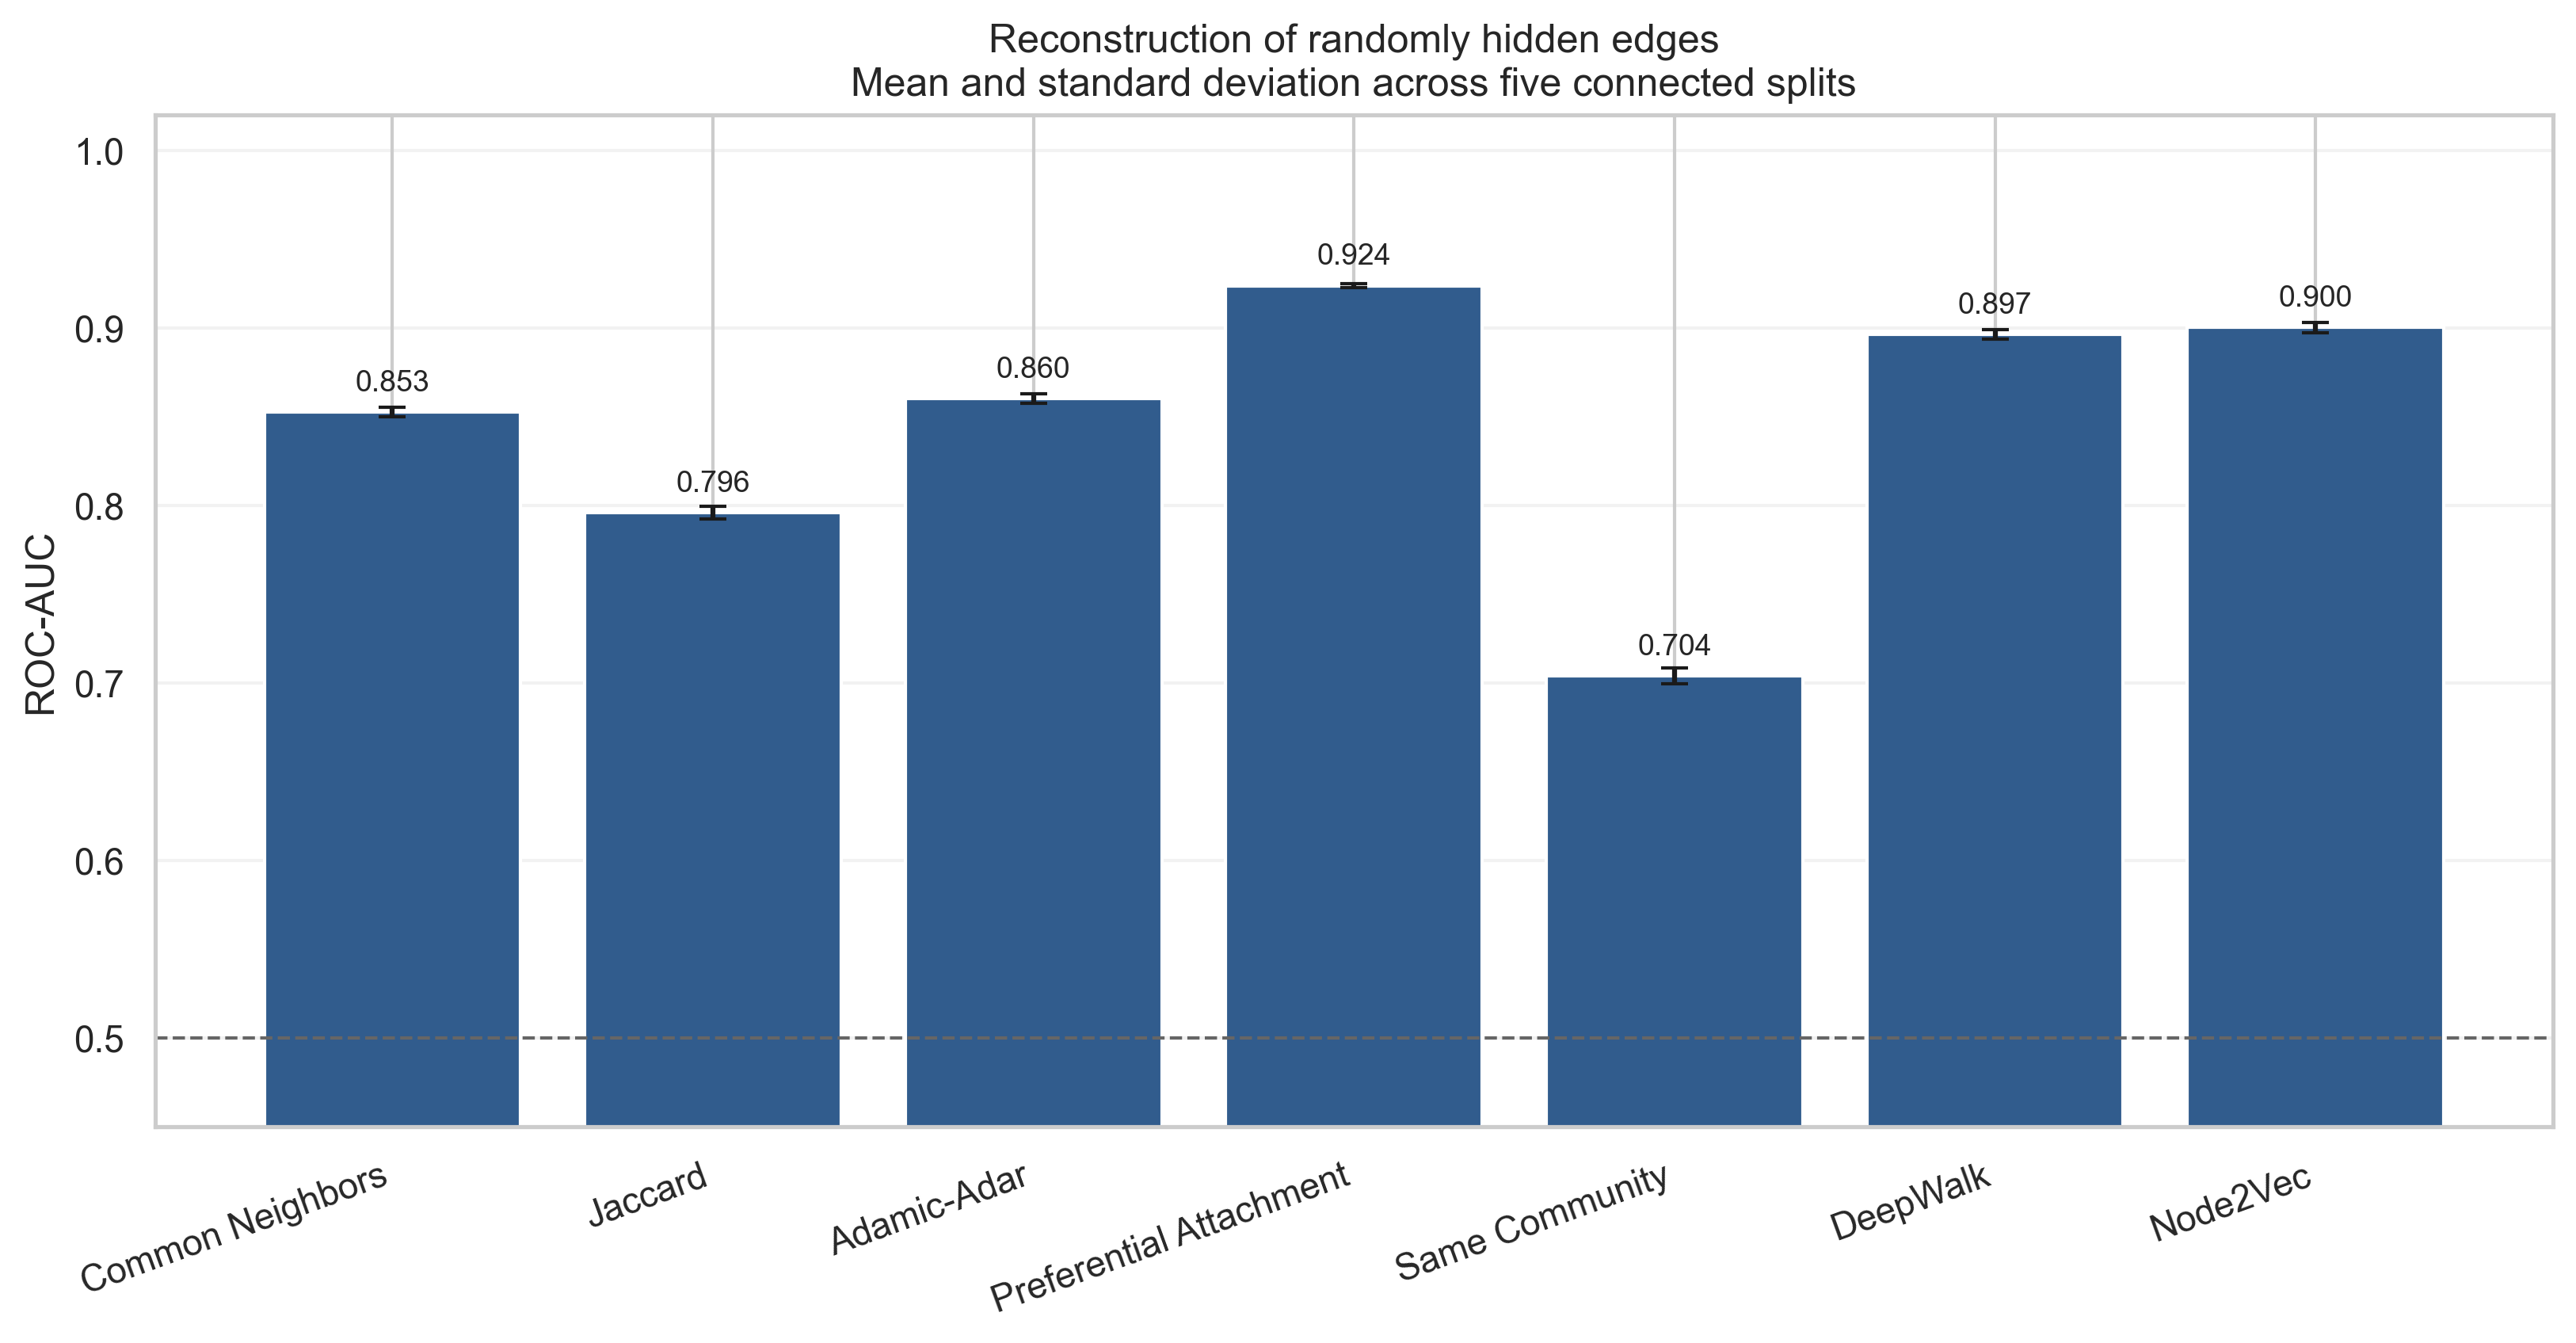

,heuristic,edge_group,n_positive_mean,n_negative_mean,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std
0,Adamic-Adar,cross-field,4261.4,4261.4,0.8294,0.0077,0.8367,0.0072
1,Adamic-Adar,same-field,24638.6,24638.6,0.8664,0.0027,0.8759,0.0025
2,Common Neighbors,cross-field,4261.4,4261.4,0.8241,0.0079,0.8197,0.0080
3,Common Neighbors,same-field,24638.6,24638.6,0.8583,0.0028,0.8540,0.0029
4,DeepWalk,cross-field,4261.4,4261.4,0.9016,0.0037,0.9131,0.0027
5,DeepWalk,same-field,24638.6,24638.6,0.8973,0.0025,0.9074,0.0023
6,Jaccard,cross-field,4261.4,4261.4,0.7969,0.0090,0.7408,0.0130
7,Jaccard,same-field,24638.6,24638.6,0.7955,0.0040,0.7077,0.0059
8,Node2Vec,cross-field,4261.4,4261.4,0.9040,0.0028,0.9158,0.0025
9,Node2Vec,same-field,24638.6,24638.6,0.9012,0.0028,0.9111,0.0024


,heuristic,roc_auc_same_minus_cross,average_precision_same_minus_cross
0,Adamic-Adar,0.0369,0.0392
1,Common Neighbors,0.0343,0.0343
2,DeepWalk,-0.0043,-0.0057
3,Jaccard,-0.0014,-0.0331
4,Node2Vec,-0.0027,-0.0047
5,Preferential Attachment,0.0082,0.0079
6,Same Community,-0.0093,-0.0227


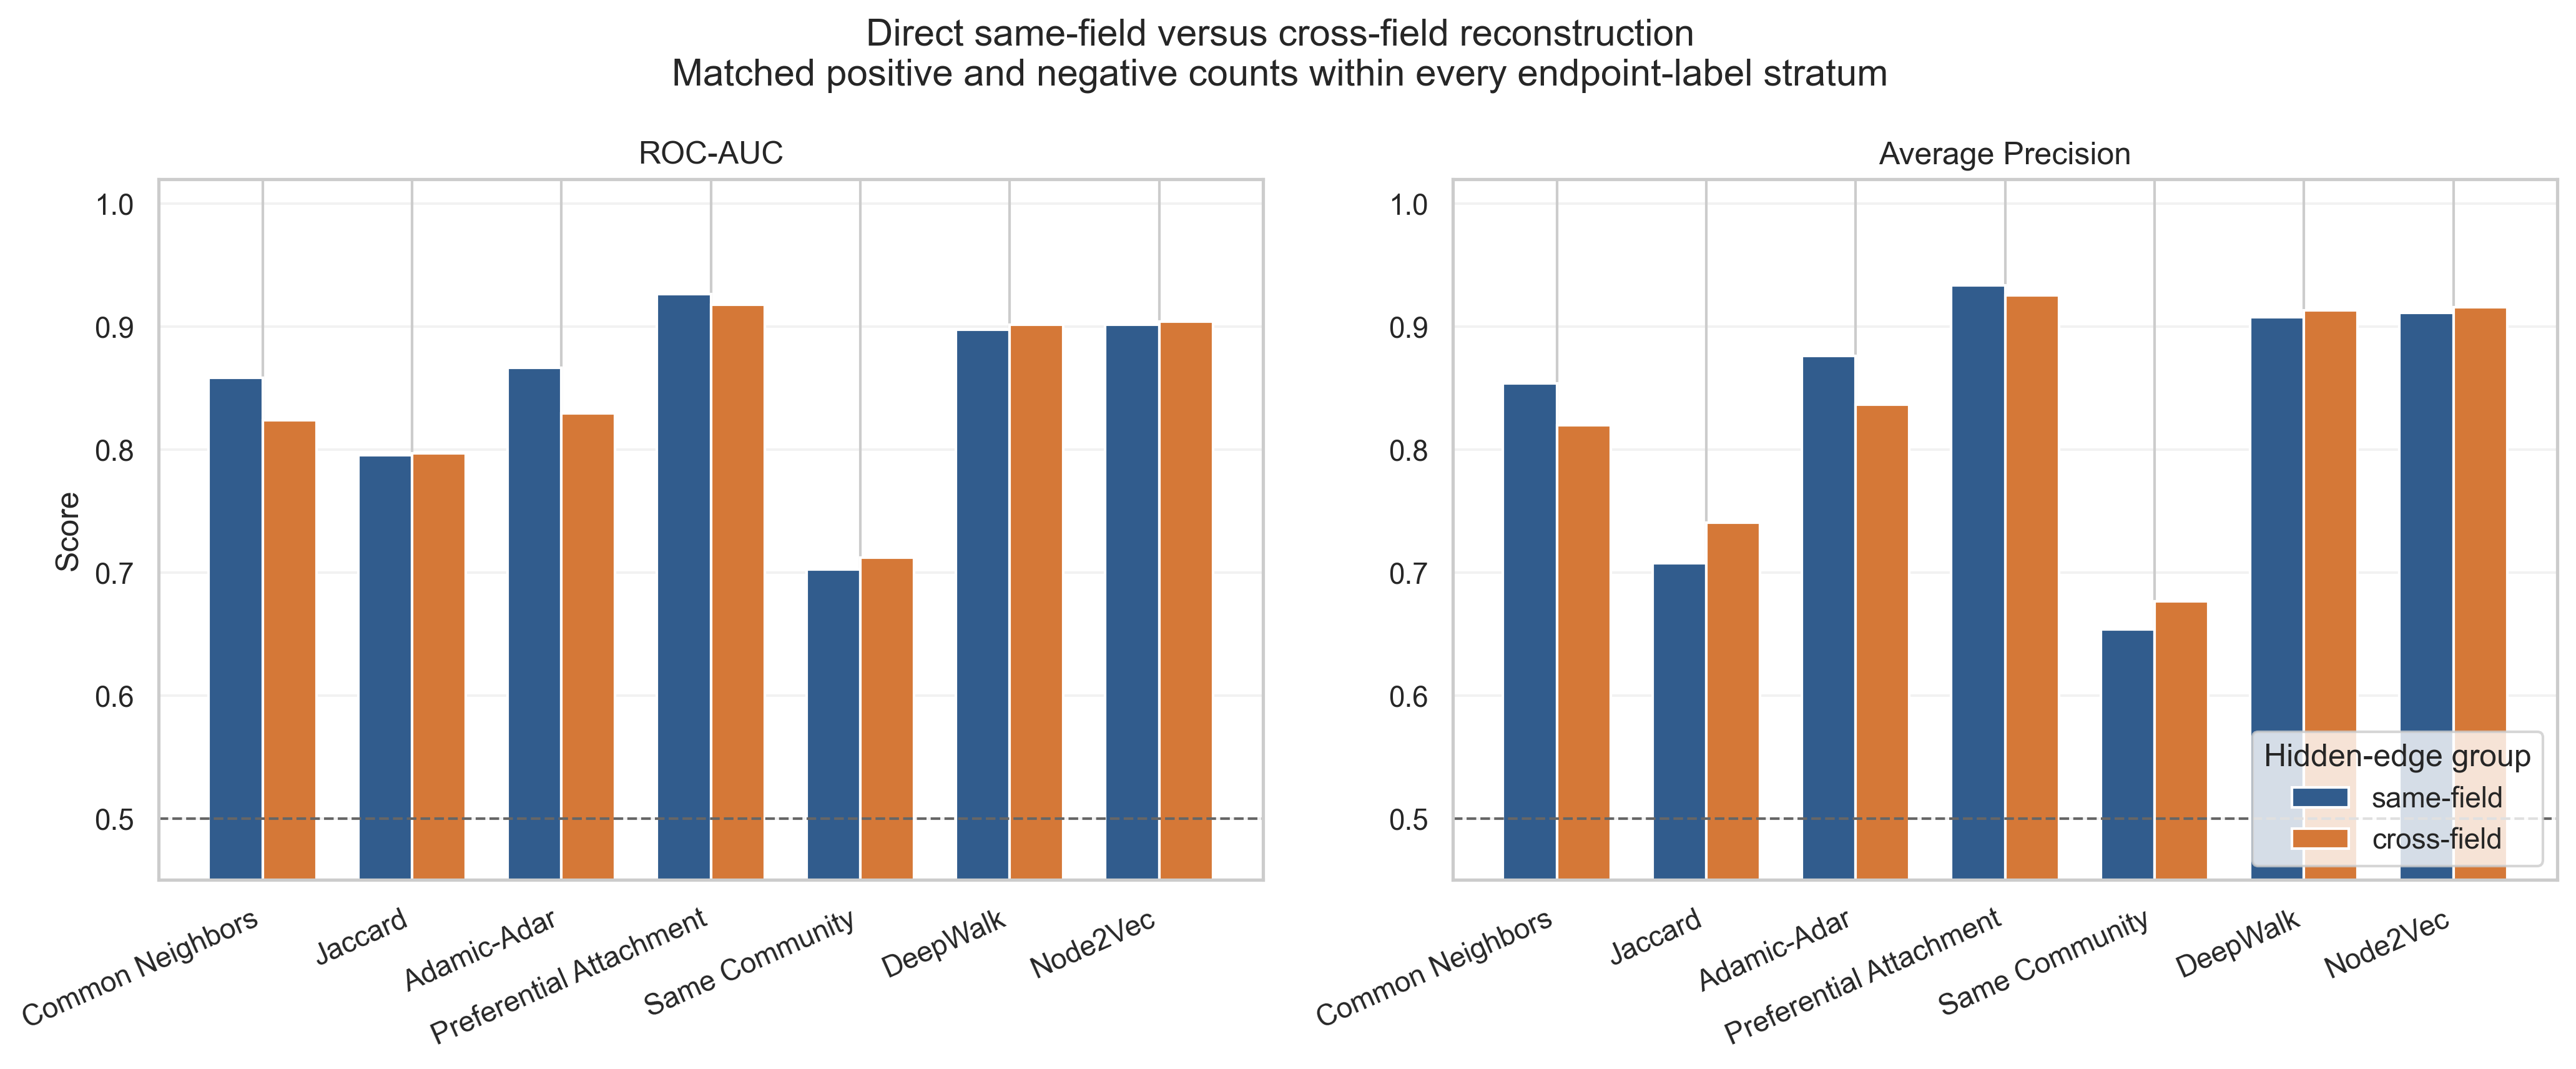

In [9]:
from run_link_prediction import main as run_edge_reconstruction
run_edge_reconstruction()
display(pd.read_csv(TABLES_DIR / "edge_split_diagnostics.csv"))
display(pd.read_csv(TABLES_DIR / "edge_reconstruction_summary.csv").round(4))
display(Image(filename=str(FIGURES_DIR / "edge_reconstruction_auc.png")))
display(pd.read_csv(TABLES_DIR / "edge_reconstruction_same_vs_cross_summary.csv").round(4))
display(pd.read_csv(TABLES_DIR / "edge_reconstruction_same_vs_cross_gaps.csv").round(4))
display(Image(filename=str(FIGURES_DIR / "edge_reconstruction_same_vs_cross.png")))

### RQ3 results

Preferential Attachment is strongest overall with ROC-AUC 0.924. For this method, same-field ROC-AUC is 0.926 versus 0.918 cross-field, a gap of 0.008; Average Precision is 0.933 versus 0.925.

Within this balanced protocol, same-field reconstruction is slightly stronger for the leading heuristic. The pattern is not universal across methods, does not identify a causal link-formation mechanism, and cannot be generalized to temporal forecasting.

## 10. RQ4 — Null models and random graph models

The analysis uses 1,000 label shuffles and 20 degree-preserving rewired graphs. Empirical p-values use the finite-simulation correction `(b+1)/(B+1)`, so they cannot be zero. Observed statistics are also compared with Erdős-Rényi, Barabási-Albert, Watts-Strogatz, and a simple degree-preserving configuration null.

Observed same-label fraction: 0.8453
Observed label assortativity: 0.3778
Null A: 1000 label shuffles ...


  done in 2.1s
Null B: 20 degree-preserving rewired graphs ...


  rewire 1/20: same-label=0.7515, modularity=0.1890 (25s)


  rewire 2/20: same-label=0.7509, modularity=0.1877 (30s)


  rewire 3/20: same-label=0.7512, modularity=0.1886 (24s)


...

  Degree-preserving configuration null done (99s)
                             network  nodes  edges  edge_count_difference_pct  max_degree  mean_degree  transitivity  avg_clustering  degree_assortativity  avg_shortest_path_sampled
                     GitHub observed  37700 289003                   0.000000        9458    15.331724      0.012357        0.167537             -0.075217                   3.217995
                         Erdos-Renyi  37700 289003                   0.000000          34    15.331724      0.000394        0.000396              0.001112                   4.125327
               Barabasi-Albert (m=8)  37700 301536                   4.336633         891    15.996605      0.002709        0.003378             -0.013764                   3.589527
        Watts-Strogatz (k=16, p=0.1)  37700 301600                   4.358778          22    16.000000      0.505876        0.511674             -0.004467                   5.551645
Degree-preserving configuration null  37

   alpha  xmin    sigma  loglik_ratio_vs_lognormal  p_vs_lognormal  loglik_ratio_vs_exponential  p_vs_exponential
2.544116  55.0 0.037774                   0.012701        0.782626                   605.791061      2.128203e-07


Saved tables and figures.


,null_model,n_samples,observed,null_mean,null_std,z_score,empirical_p
0,label_shuffle,1000,0.845344,0.616599,0.011765,19.442172,0.000999
1,degree_preserving_rewire,20,0.845344,0.751256,0.000525,179.084612,0.047619


,observed_modularity,rewired_null_mean,rewired_null_std,z_score,n_rewires,empirical_p
0,0.453448,0.188541,0.000778,340.357861,20,0.047619


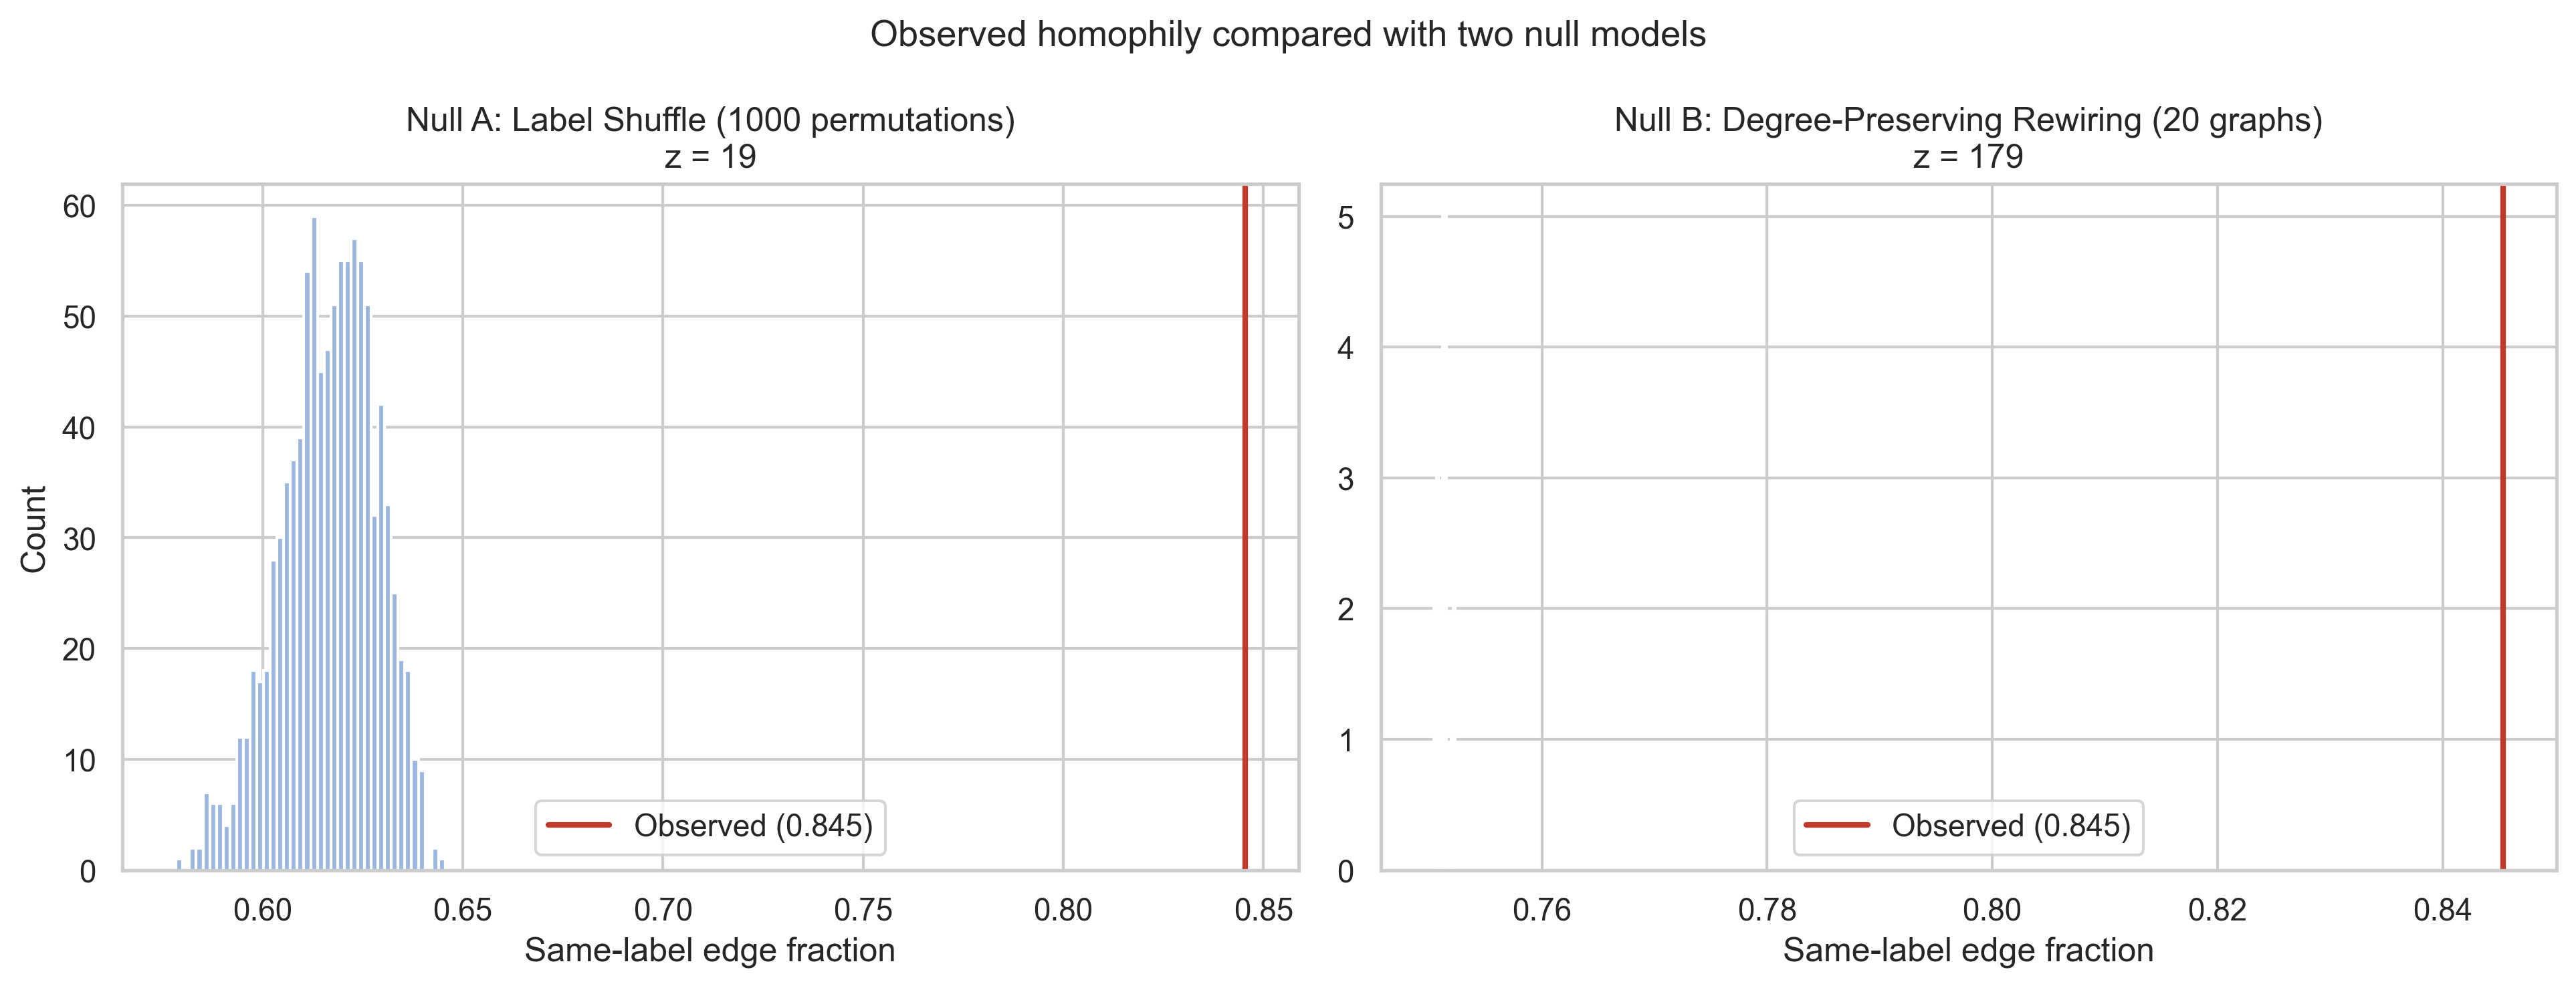

,network,nodes,edges,edge_count_difference_pct,max_degree,mean_degree,transitivity,avg_clustering,degree_assortativity,avg_shortest_path_sampled
0,GitHub observed,37700,289003,0.0000,9458,15.3317,0.0124,0.1675,-0.0752,3.2180
1,Erdos-Renyi,37700,289003,0.0000,34,15.3317,0.0004,0.0004,0.0011,4.1253
2,Barabasi-Albert (m=8),37700,301536,4.3366,891,15.9966,0.0027,0.0034,-0.0138,3.5895
3,"Watts-Strogatz (k=16, p=0.1)",37700,301600,4.3588,22,16.0000,0.5059,0.5117,-0.0045,5.5516
4,Degree-preserving configuration null,37700,289003,0.0000,9458,15.3317,0.0122,0.0914,-0.0713,3.1561


,alpha,xmin,sigma,loglik_ratio_vs_lognormal,p_vs_lognormal,loglik_ratio_vs_exponential,p_vs_exponential
0,2.5441,55.0,0.0378,0.0127,0.7826,605.7911,0.0


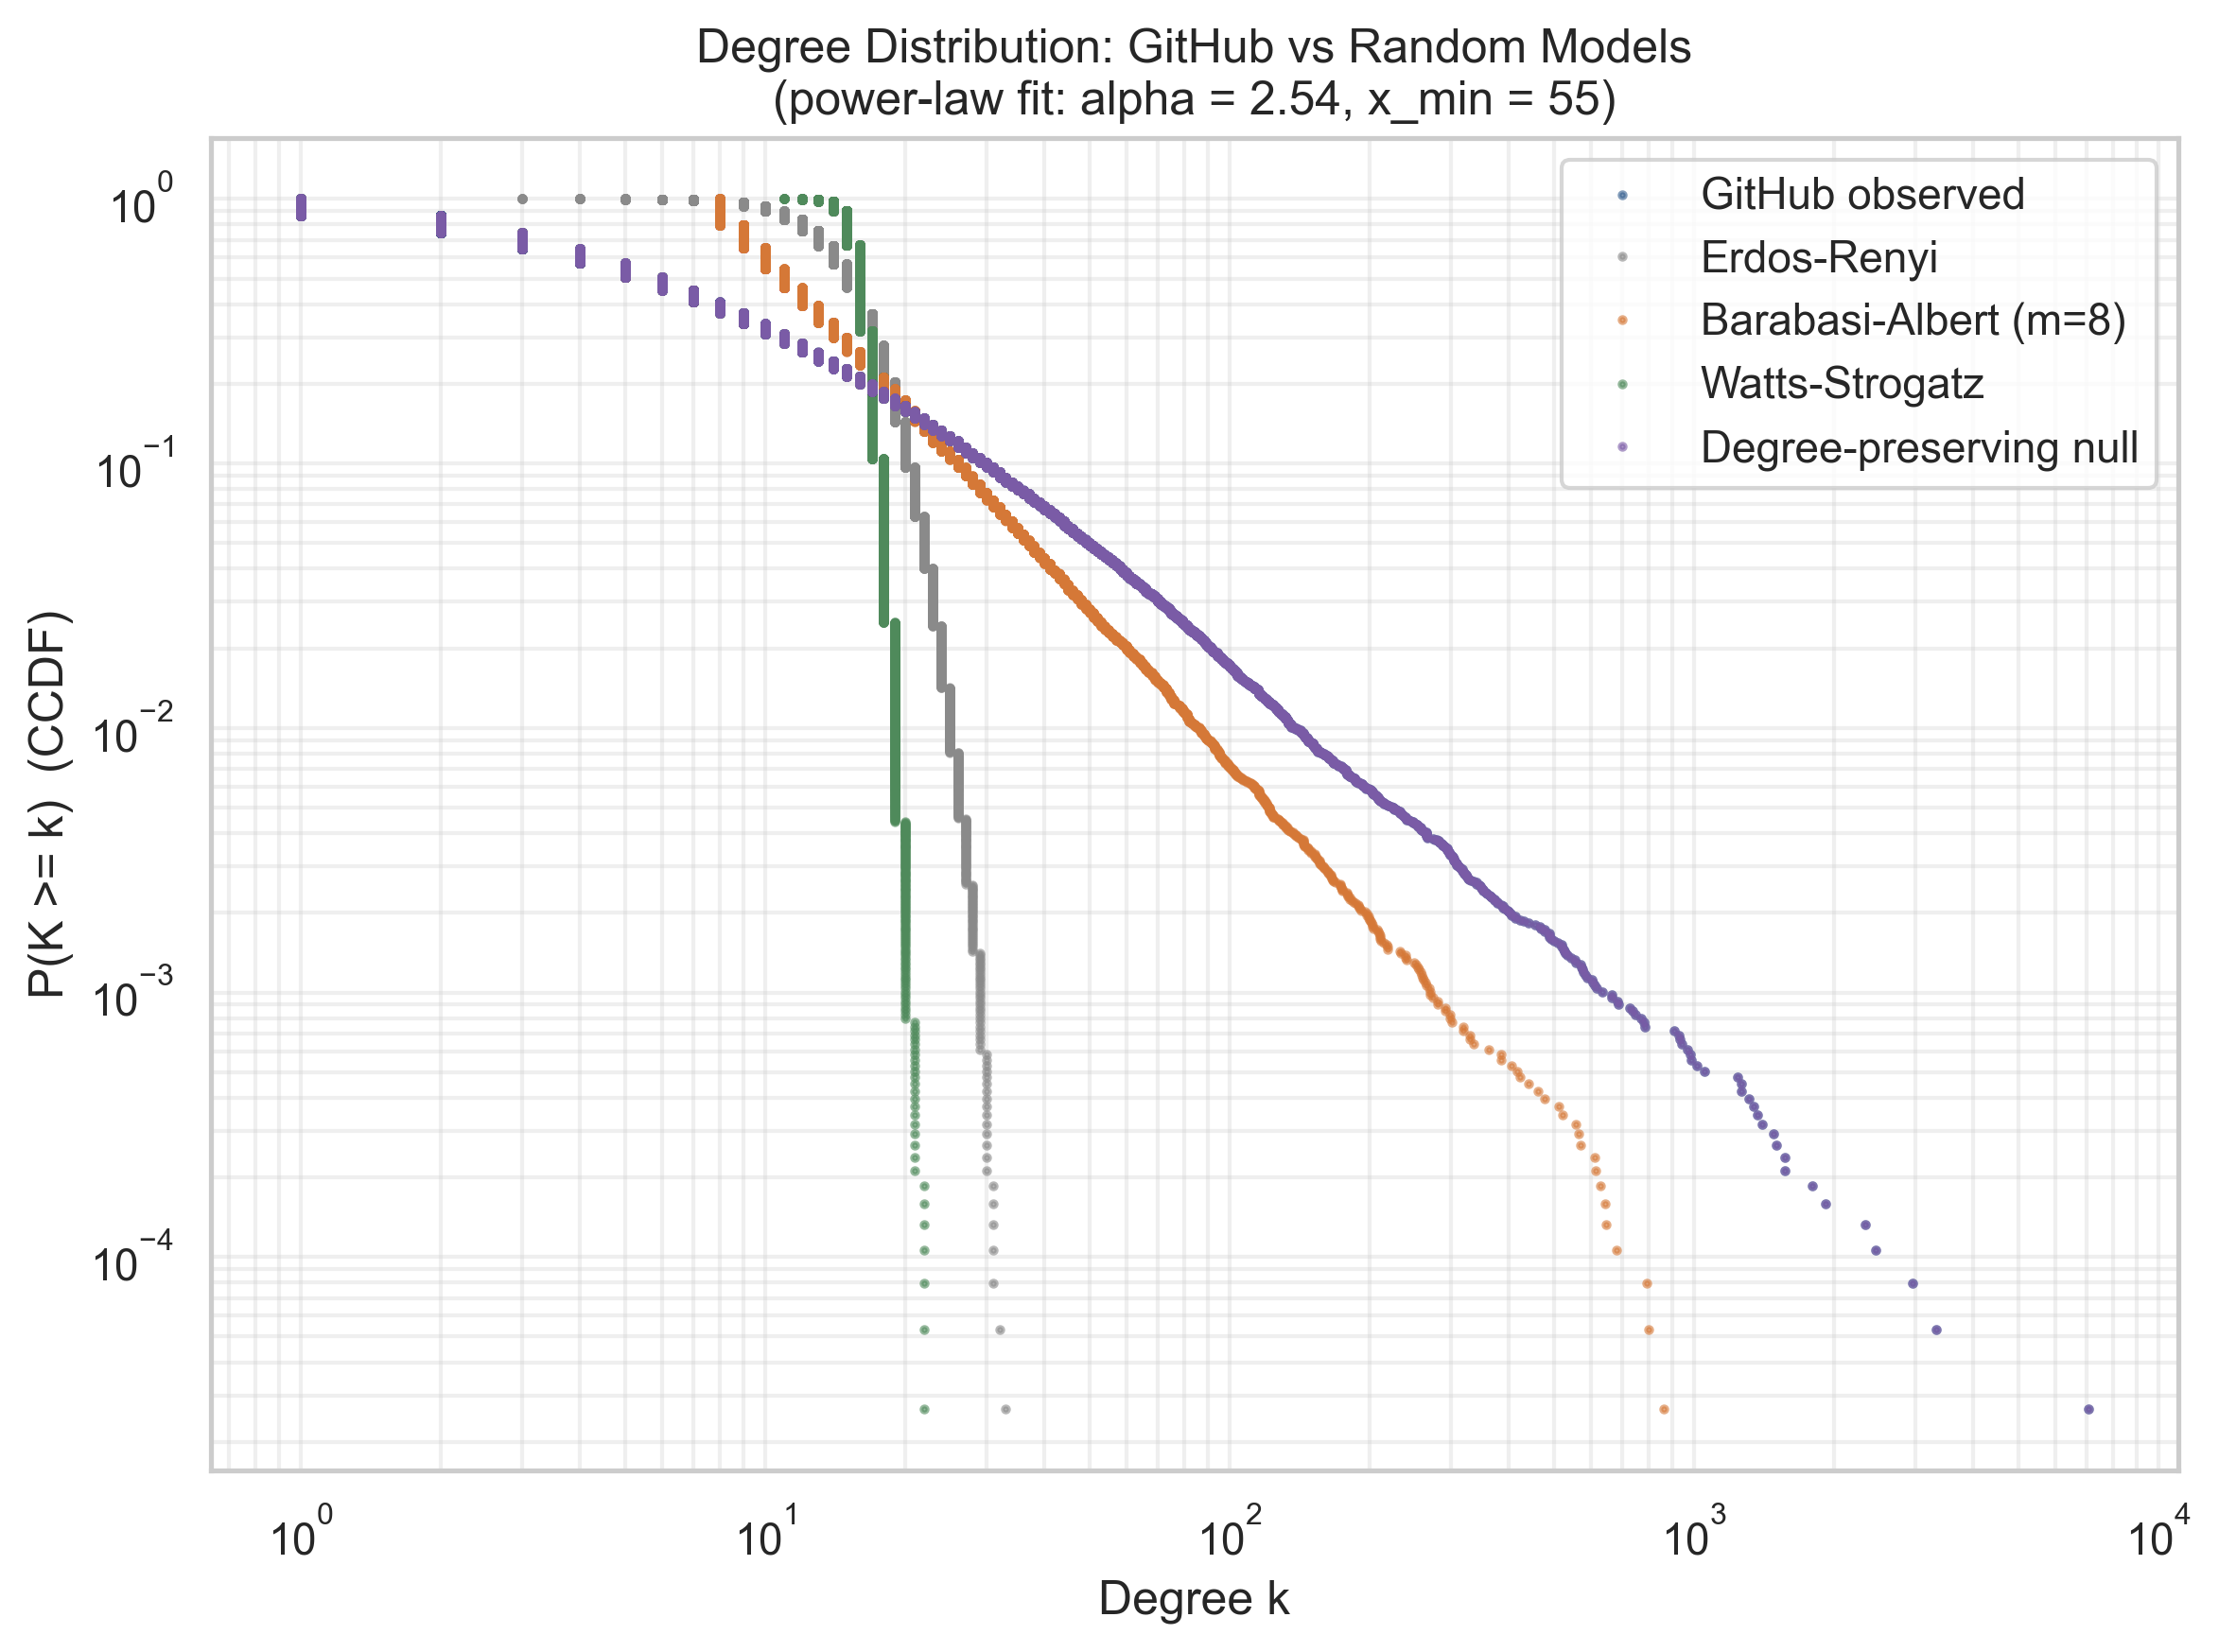

In [10]:
from run_null_models import main as run_null_models
run_null_models()
display(pd.read_csv(TABLES_DIR / "null_model_homophily.csv").round(6))
display(pd.read_csv(TABLES_DIR / "null_model_modularity.csv").round(6))
display(Image(filename=str(FIGURES_DIR / "homophily_null_distribution.png")))
display(pd.read_csv(TABLES_DIR / "network_vs_random_models.csv").round(4))
display(pd.read_csv(TABLES_DIR / "powerlaw_fit.csv").round(4))
display(Image(filename=str(FIGURES_DIR / "degree_distribution_loglog.png")))

### RQ4 results

- Observed homophily is 0.845, versus 0.617 under label shuffling and 0.751 under degree-preserving rewiring. Corrected p-values are 0.000999 and 0.047619.
- Observed modularity is 0.453, versus 0.189 in rewired graphs; empirical p=0.047619.
- Observed average clustering is 0.168, versus 0.0004 in ER, 0.0034 in BA, 0.512 in Small-World, and 0.091 in the degree-preserving configuration null.
- The fitted tail exponent is α=2.54, but the comparison with lognormal does not justify a blanket scale-free claim. The defensible conclusion is a heavy-tailed degree distribution.

## 11. Discussion, limitations, and conclusions

The main conclusion is that network structure contains useful information about developer field, especially through communities and learned graph representations. Content features are also strong, and the hybrid model performs best. The limitations are the static 2019 snapshot, the binary target label, approximate centrality, and static reconstruction of hidden edges.

## 12. References

1. Rozemberczki, B., Allen, C., & Sarkar, R. (2019). *Multi-scale Attributed Node Embedding (MUSAE)*.
2. Blondel, V. D., et al. (2008). *Fast unfolding of communities in large networks*.
3. Perozzi, B., Al-Rfou, R., & Skiena, S. (2014). *DeepWalk*.
4. Grover, A., & Leskovec, J. (2016). *node2vec: Scalable Feature Learning for Networks*.
5. Liben-Nowell, D., & Kleinberg, J. (2003). *The Link Prediction Problem for Social Networks*.
6. Clauset, A., Shalizi, C. R., & Newman, M. E. J. (2009). *Power-law distributions in empirical data*.
7. Page, L., et al. (1999). *The PageRank Citation Ranking*.
8. Course lectures and tutorials on centrality, communities, network models, link reconstruction, and graph embeddings.

## 13. Project check

This final cell checks that the consolidated notebook agrees with the saved result tables and required project artifacts.

In [11]:
from final_validation import run_all_validations
run_all_validations(PROJECT_DIR, verify_notebook_execution=False)

ALL FINAL PROJECT VALIDATIONS PASSED


**Result.** The success message confirms that the consolidated notebook agrees with the current result tables and satisfies the original artifact checks.

## Summary

This consolidated notebook presents the same project in one compact workflow. Main finding: network structure, content features, learned representations, and null models all show a strong descriptive link between developer field and the mutual-follow network.